# Run if on Google Colab

In [ ]:
%pip install git+https://github.com/deepmind/dm-haiku
%pip install jaxopt
%pip install optax

  Cloning https://github.com/deepmind/dm-haiku to /tmp/pip-req-build-sk1e77ox
  Running command git clone --filter=blob:none --quiet https://github.com/deepmind/dm-haiku /tmp/pip-req-build-sk1e77ox
  Resolved https://github.com/deepmind/dm-haiku to commit 47500fbd438565b73508e3f443cdda85be26f39d
  Preparing metadata (setup.py) ... done
  Created wheel for dm-haiku: filename=dm_haiku-0.0.17.dev0-py3-none-any.whl size=374528 sha256=10b08b0d728599a3e63b9f1faed9992964e368f45d4cd27cd61592c945038580
  Stored in directory: /tmp/pip-ephem-wheel-cache-tz22t9nq/wheels/9e/61/4f/80a3533070997bbf330ff52c178cc780d5e60ad222899e2924
Successfully built dm-haiku
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.4/172.4 kB 9.6 MB/s eta 0:00:00


In [ ]:
# Set-up google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/MyDrive/My Research/Dynamic Mechanism Design

/content/drive/MyDrive/My Research/Dynamic Mechanism Design


# Set up Environment

In [ ]:
# Import packages
from typing import NamedTuple, Callable, Dict, List, Tuple
import functools
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import haiku as hk
import numpy as np
import optax
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import time
from itertools import product
import pickle
from flax import struct
# from mynetworks import *
# from myjaxutil import *
import os
import itertools


#Set seed
SEED = 42
ZERO_CLIP_MIN = 1e-4

# Plotting Method

In [ ]:
def plot_loss_dict(losses, title = ""):
    num_losses = len(losses)
    num_rows = (num_losses - 1) // 3 + 1
    fig, axs = plt.subplots(num_rows, 3, figsize=(10, 3*num_rows))
    for i, (name, loss) in enumerate(losses.items()):
        row = i // 3
        col = i % 3
        if num_rows == 1:
            axs[col].plot(loss)
            axs[col].set_title(name, fontsize=8)
            continue
        axs[row, col].plot(loss)
        axs[row, col].set_title(name, fontsize=8)

    fig.suptitle(title, fontsize=16)  # Customize the title and font size
    plt.tight_layout(rect=[0, 0, 1, 1])

    plt.show()

def plot_loss_overlay_dict(losses, print_iter, title = ""):
    num_plots = len(losses)  # Number of subplots needed
    num_cols = 3  # Number of columns per row
    num_rows = (num_plots - 1) // num_cols + 1

    fig, axs = plt.subplots(num_rows, num_cols, figsize=(10, 3 * num_rows))

    # Flatten axs array for easy indexing and handle cases where axs is not an array
    if num_rows * num_cols == 1:
        axs = [axs]
    else:
        axs = axs.flatten()

    # Iterate over the plots and their corresponding data
    for i, (plot_title, curves_dict) in enumerate(losses.items()):
        ax = axs[i]
        for legend_title, loss_values in curves_dict.items():
            x_axis = np.array(range(0, len(loss_values)))* print_iter
            ax.plot(x_axis, loss_values, label=legend_title)
        ax.set_title(plot_title)
        ax.legend()
        ax.set_xlabel("Iterations")  # Default x-axis label
        ax.set_ylabel("Normalized Values")  # Default y-axis label

    # Remove any unused subplots
    for j in range(num_plots, len(axs)):
        fig.delaxes(axs[j])

    fig.suptitle(title, fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 1])
    plt.show()



def plot_loss_dicts(loss_dicts, print_iter = 50, dict_names=None, title="",
                    row_label_pos="above",   # "above" or "below"
                    label_pad=0.06):         # fraction of that row's height
    """
    Grid: rows = loss keys, cols = dictionaries.
    Row labels are placed using the actual axes positions after layout,
    so they align perfectly with each row.

    label_pad is a fraction of the row height (not the whole figure).
    """
    if not loss_dicts:
        raise ValueError("loss_dicts must be non-empty")

    n = len(loss_dicts)
    if dict_names is None:
        dict_names = [f"Dict {i+1}" for i in range(n)]
    if len(dict_names) != n:
        raise ValueError("dict_names length must match number of dictionaries")

    # common keys, preserving first dict's order
    first_keys = list(loss_dicts[0].keys())
    common_keys = [k for k in first_keys if all(k in d for d in loss_dicts)]
    if not common_keys:
        raise ValueError("No common keys across dictionaries")

    rows, cols = len(common_keys), n
    fig, axs = plt.subplots(rows, cols, figsize=(4.0*cols, 2.3*rows), sharex="col")

    # make axs a (rows, cols) array
    if rows == 1 and cols == 1:
        axs = np.array([[axs]])
    elif rows == 1:
        axs = np.array([axs])
    elif cols == 1:
        axs = np.array([[ax] for ax in axs])

    # plot
    for r, key in enumerate(common_keys):
        for c, (name, dct) in enumerate(zip(dict_names, loss_dicts)):
            ax = axs[r, c]
            y = dct[key]
            # SCALE X BY print_iter SO TICKS SHOW TRUE EPOCHS
            x = np.arange(len(y)) * print_iter
            ax.plot(x, y)
            ax.grid(True, alpha=0.25)
            if r == 0:  # column titles on first row
                ax.set_title(name, fontsize=10)
            if r == rows - 1:
                ax.set_xlabel("epoch")

    if title:
        fig.suptitle(title, fontsize=14, y=0.995)

    # layout first, so axes positions are final
    fig.tight_layout(rect=[0.03, 0.03, 0.97, 0.96])
    fig.canvas.draw()  # ensure positions are updated

    # place a centered label per row using actual axes bounds
    for r in range(rows):
        row_axes = axs[r, :].ravel()
        # bounds in figure coords
        row_left   = min(ax.get_position().x0 for ax in row_axes)
        row_right  = max(ax.get_position().x1 for ax in row_axes)
        row_bottom = min(ax.get_position().y0 for ax in row_axes)
        row_top    = max(ax.get_position().y1 for ax in row_axes)
        row_height = row_top - row_bottom

        x_center = 0.5 * (row_left + row_right)
        if row_label_pos.lower() in ("above", "top"):
            y = row_top + label_pad * row_height
            va = "bottom"
        else:  # "below"
            y = row_bottom - label_pad * row_height
            va = "top"

        # clamp a bit to avoid clipping
        y = max(0.002, min(0.998, y))

        fig.text(x_center, y, common_keys[r],
                 ha="center", va=va, fontsize=11, fontweight="bold",
                 transform=fig.transFigure)

    plt.show()


def plot_loss_overlay_dict(losses, print_iter, title = ""):
    num_plots = len(losses)  # Number of subplots needed
    num_cols = 3  # Number of columns per row
    num_rows = (num_plots - 1) // num_cols + 1

    fig, axs = plt.subplots(num_rows, num_cols, figsize=(10, 3 * num_rows))

    # Flatten axs array for easy indexing and handle cases where axs is not an array
    if num_rows * num_cols == 1:
        axs = [axs]
    else:
        axs = axs.flatten()

    # Iterate over the plots and their corresponding data
    for i, (plot_title, curves_dict) in enumerate(losses.items()):
        ax = axs[i]
        for legend_title, loss_values in curves_dict.items():
            x_axis = np.array(range(0, len(loss_values)))* print_iter
            ax.plot(x_axis, loss_values, label=legend_title)
        ax.set_title(plot_title)
        ax.legend()
        ax.set_xlabel("Iterations")  # Default x-axis label
        ax.set_ylabel("Normalized Values")  # Default y-axis label

    # Remove any unused subplots
    for j in range(num_plots, len(axs)):
        fig.delaxes(axs[j])

    fig.suptitle(title, fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 1])
    plt.show()

# Bandit Auction

- Option A: Explicit Belief Tracking

  - Maintain a probability distribution $ b_t(s) = P(s_t \mid h_t) $ over latent states.
  - Update beliefs using a **Bayes filter**:

    $$
    b_{t+1}(s') \propto \sum_s P(s' \mid s, a_t) \cdot P(o_{t+1} \mid s') \cdot b_t(s)
    $$

  - This requires known dynamics $ P $.

- Option B: Implicit Belief via Recurrent Networks

- Use an Transformer/RNN to encode observation-action history into a belief embedding:

  $$
  b_t = \text{Trans/RNN}_\phi(b_{t-1}, o_t, a_{t-1})
  $$


## Bandit Auction Class

In [ ]:
@struct.dataclass
class State:
    """A class that stores the state of the auction."""
    time_step: int
    allocation_history: jnp.ndarray # (num_horizons, num_buyers, num_goods)
    current_type: jnp.ndarray # (num_buyers, num_goods)
    report_history: jnp.ndarray # (num_horizons, num_buyers, num_goods)

    def replace_state(self, new_time_step, new_allocation_history, new_current_type, new_report_history):
        new_state = self.replace(time_step = new_time_step, allocation_history = new_allocation_history, current_type = new_current_type, report_history = new_report_history) # type: ignore
        return new_state

    def replace_buyer_type(self, buyer, buyer_type):
        new_type = self.current_type.at[buyer].set(buyer_type)
        new_state = self.replace(current_type = new_type)
        return new_state


    def __eq__(self, other):
        return (
            self.time_step == other.time_step and
            jnp.all(self.allocation_history == other.allocation_history) and
            jnp.all(self.current_type == other.current_type) and
            jnp.all(self.report_history == other.report_history)
        )


    def _hash_array(self, arr: jnp.ndarray):
        return hash(arr.tobytes()) ^ hash(arr.shape) ^ hash(arr.dtype)


    def __hash__(self):
        return hash((
            self.time_step,
            self._hash_array(self.allocation_history),
            self._hash_array(self.current_type),
            self._hash_array(self.report_history),
        ))



@struct.dataclass
class BeliefState:
    time_step: int
    allocation_history: jnp.ndarray                         # (T, B, G)
    pub_embed: jnp.ndarray                                  # (d_pub,)
    priv_embeds: jnp.ndarray                                # (B, d_priv)  <-- one per buyer
    report_history: jnp.ndarray                             # (T, B, G)

    def replace_state(self, new_time_step, new_allocation_history, new_pub_embed, new_priv_embeds, new_report_history):
        return self.replace(
            time_step=new_time_step,
            allocation_history=new_allocation_history,
            pub_embed=new_pub_embed,
            priv_embeds=new_priv_embeds,
            report_history=new_report_history
        )


@struct.dataclass
class BeliefModel:
    """A class that stores the networks and parameters of a belief model."""
    pub_net: hk.Transformed     # (c_t, o_pub_t) -> c_{t+1}
    pub_params: hk.Params
    priv_net: hk.Transformed    # (h_i,t, concat(o_priv_i,t, proj(c_{t+1}))) -> h_{i, t+1}
    priv_params: hk.Params
    d_pub: int
    d_priv: int




@struct.dataclass
class BanditAuction:
    """A class that stores the parameters of a bandit auction."""
    num_horizons: int = struct.field(pytree_node=False)
    num_buyers: int = struct.field(pytree_node=False)
    num_goods: int = struct.field(pytree_node=False)
    init_state_function: Callable[["BanditAuction", jax.random.PRNGKey], State] = struct.field(pytree_node=False)
    init_belief_state_function: Callable[["BanditAuction", State], BeliefState] = struct.field(pytree_node=False)
    get_transition_prob: Callable = struct.field(pytree_node=False)
    transition_function: Callable[["BanditAuction", int, jnp.ndarray, jnp.ndarray, jax.random.PRNGKey], State] = struct.field(pytree_node=False) # p(t, type, alloc_hist, key) -> type'
    discount: float = struct.field(pytree_node=False)
    allocation_cost: jnp.ndarray = struct.field(pytree_node=False)
    # Continuous type sampler. Signature: f(key) -> (B,G)
    sample_types_fn: Callable[[jax.random.PRNGKey], jnp.ndarray] = struct.field(pytree_node=False)
    types_low: jnp.ndarray = struct.field(pytree_node=False)
    types_high: jnp.ndarray = struct.field(pytree_node=False)
    # Latent belief encoder:
    belief_pub_net: hk.Transformed = struct.field(pytree_node=False)
    belief_pub_params: hk.Params = struct.field(pytree_node=False)
    belief_priv_net: hk.Transformed = struct.field(pytree_node=False)
    belief_priv_params: hk.Params = struct.field(pytree_node=False)
    d_pub: int = struct.field(pytree_node=False, default=64)
    d_priv: int = struct.field(pytree_node=False, default=128)

    def get_initial_state(self, key):
        return self.init_state_function(self, key)

    def get_initial_belief_state(self, state):
        return self.init_belief_state_function(self, state)

    def get_next_state(self, state, report, allocation, key):
        time_step = state.time_step
        new_time_step = time_step + 1
        new_allocation_history = state.allocation_history.at[time_step].set(allocation)
        new_current_type = self.transition_function(self, time_step, state.current_type, new_allocation_history, key)
        new_report_history = state.report_history.at[time_step].set(report)
        return state.replace_state(new_time_step, new_allocation_history, new_current_type, new_report_history)


    ######### New belief state update
    ### Encode observations
    def encode_obs_pub(self, t: int, allocation_t: jnp.ndarray) -> jnp.ndarray:
        # (d_obs_pub) = 1 + B*G
        parts = [
            jnp.array([t / max(1, self.num_horizons - 1)], dtype=jnp.float32),   # (1,)
            allocation_t.reshape(-1).astype(jnp.float32)                            # (B*G,)
        ]
        return jnp.concatenate(parts, axis=0)  # (1 + B*G,)

    def encode_obs_priv_i(self, t: int, type_i_next: jnp.ndarray, report_it: jnp.ndarray) -> jnp.ndarray:
        # (d_obs_priv) = 1 + 2G
        parts = [
            jnp.array([t / max(1, self.num_horizons - 1)], dtype=jnp.float32),   # (1,)
            type_i_next.reshape(-1).astype(jnp.float32),                             # (G,)
            report_it.reshape(-1).astype(jnp.float32)                               # (G,)
        ]
        return jnp.concatenate(parts, axis=0)  # (1 + 2G,)

    def get_next_belief_state(self, belief_state, report, allocation, next_state):
        # t and histories
        t = belief_state.time_step
        new_time_step = t + 1
        new_allocation_history = belief_state.allocation_history.at[t].set(allocation)
        new_report_history     = belief_state.report_history.at[t].set(report)

        # --- Public update (allocations are public; reports are NOT) ---
        o_pub_t = self.encode_obs_pub(t, allocation)
        c_next  = self.belief_pub_net.apply(self.belief_pub_params, belief_state.pub_embed, o_pub_t)

        # --- Private updates (one per buyer), conditioned on c_next ---
        def update_one(i, h_i):
            type_i_next = next_state.current_type[i]   # buyer i's type at t+1 (if observed by buyer i)
            report_it   = report[i]                    # buyer i's report at time t (private)
            o_priv_i    = self.encode_obs_priv_i(t, type_i_next, report_it)
            return self.belief_priv_net.apply(self.belief_priv_params, h_i, o_priv_i, c_next)

        h_next = jax.vmap(update_one, in_axes=(0, 0))(jnp.arange(self.num_buyers), belief_state.priv_embeds)

        # return updated belief state
        return belief_state.replace_state(new_time_step, new_allocation_history, c_next, h_next, new_report_history)



@struct.dataclass
class Mechanism:
    """A class that stores the network and parameters of a mechanism, and applies the mechanism to a state.
    Attributes:
        network: A Haiku network.
        params: The parameters of the network.
    """

    network: hk.Transformed = struct.field(pytree_node=False)
    params: hk.Params

    def __call__(self, state: State, report: jnp.ndarray, auction: BanditAuction, *args) -> jnp.ndarray:
        """Applies the mechanism to a state.
        Args:
            state: A state of the economy.
            reprot: The report of the consumer.
        Returns:
            The output (allocation probability and payment) of the network for the given state.
        """
        allocation_probs, payment = self.network.apply(self.params, state, report, auction, *args)

        return allocation_probs[:-1], payment





# @struct.dataclass
# class ContPolicy:
#     network: hk.Transformed = struct.field(pytree_node=False)
#     params: hk.Params

#     def __call__(self, belief_state: BeliefState, auction: BanditAuction,
#                  key: jax.random.PRNGKey, types_low: jnp.ndarray, types_high: jnp.ndarray, *args):
#         report = self.network.apply(self.params, belief_state, auction, types_low, types_high, *args)
#         return report



@struct.dataclass
class BoundedContPolicy:
    network: hk.Transformed = struct.field(pytree_node=False)
    params: hk.Params
    def __call__(self, belief_state: BeliefState, auction: BanditAuction,
                 key: jax.random.PRNGKey, *args):
        report = self.network.apply(self.params, belief_state, auction, *args)
        return report  # deterministic policy



@struct.dataclass
class DiffPolicy:
    network: hk.Transformed = struct.field(pytree_node=False)
    params: hk.Params
    temperature: float = 1.0
    # mode: str = "gumbel"    # "soft" | "gumbel" | "st"

    def __call__(self, belief_state: BeliefState, auction: BanditAuction,
                 key: jax.random.PRNGKey, *args) -> jnp.ndarray:
        """
        Returns a continuous report: (B, G)
        logits = network(belief_state) -> (B, K)
        buyer_types = (B, K, G) prototypes
        """
        logits = self.network.apply(self.params, belief_state, auction, *args)  # (B, K)
        B, K = logits.shape

        # Build (B, K, G)
        buyer_types_stack = jnp.stack(
            [jnp.asarray(ty, dtype=jnp.float32) for ty in auction.buyer_types], axis=0
        )  # (B, K, G)

        tau = self.temperature

        # if self.mode == "soft":
        #     # Deterministic soft-argmax approximation to argmax(logits)
        #     y = jax.nn.softmax(logits / tau, axis=-1)           # (B, K)

        # elif self.mode == "gumbel":
        # Reparameterized Gumbel-Softmax (stochastic, differentiable)
        g = -jnp.log(-jnp.log(jax.random.uniform(
            key, shape=logits.shape, minval=1e-6, maxval=1 - 1e-6)))
        y = jax.nn.softmax((logits + g) / tau, axis=-1)     # (B, K)

        # elif self.mode == "st":
        #     # Straight-through Gumbel-Softmax (hard forward, soft backward)
        #     g = -jnp.log(-jnp.log(jax.random.uniform(
        #         key, shape=logits.shape, minval=1e-6, maxval=1 - 1e-6)))
        #     y_soft = jax.nn.softmax((logits + g) / tau, axis=-1)     # (B, K)
        #     hard_idx = jnp.argmax(y_soft, axis=-1)                   # (B,)
        #     y_hard  = jax.nn.one_hot(hard_idx, K, dtype=y_soft.dtype)  # (B, K)
        #     y = y_hard + jax.lax.stop_gradient(y_soft - y_hard)      # ST trick
        # else:
        #     raise ValueError(f"Unknown mode: {self.mode}")

        # Map mixture over prototypes to a report vector in R^G
        # (B, K) x (B, K, G) -> (B, G)
        report = jnp.einsum("bk,bkg->bg", y, buyer_types_stack)
        return report



@struct.dataclass
class Value:
    """A class that stores network and parameters for a cumulative regret value function, and applies the cumulative regret value function to a belief state.
    Attributes:
        network: A Haiku network.
        params: The parameters of the network.
    """
    network: hk.Transformed = struct.field(pytree_node=False)
    params: hk.Params

    def __call__(self, belief_state: BeliefState, auction: BanditAuction, *args) -> jnp.ndarray:
        """Applies the cumulative regret value function to a belief state.
        Args:
            belief state: A belief state of the economy.
        Returns:
            The output (cumulative regret value) of the network for the given belief state.
        """
        return self.network.apply(self.params, belief_state, auction, *args)



@struct.dataclass
class Episode:
    state: State
    belief_state: BeliefState
    report: jnp.ndarray
    log_prob: float
    allocation: jnp.ndarray
    payments: jnp.ndarray
    value: float
    rewards: jnp.ndarray = struct.field(default_factory=jnp.ndarray)
    regret: float = struct.field(default=0.0)

## Auction Simulator

In [ ]:
class AuctionSimulator:


    @staticmethod
    @jax.jit
    def get_rewards(auction: BanditAuction, state: State, allocation: jnp.ndarray, payment: jnp.ndarray) -> jnp.ndarray:
        """A function that takes the allocation and returns the instantaneous rewards of the buyer.
        Args:
            auction: An instance of the BanditAuction class.
            state: The current state of the auction.
            allocation: The allocation of the good.
            payment: The payment of the buyers.
        Returns:
            The rewards, which is a vector of length num_buyers.
        """
        # return jnp.sum(allocation*state.current_type, axis = 1).clip(ZERO_CLIP_MIN)
        return jnp.sum(allocation*state.current_type, axis = 1) - payment


    @staticmethod
    @jax.jit
    def get_profit(auction: BanditAuction, state: State, allocation: jnp.ndarray, payment: jnp.ndarray) -> float:
        """A function that takes the allocation and returns the instantaneous profit of the seller.
        Args:
            auction: An instance of the BanditAuction class.
            state: The current state of the auction.
            allocation: The allocation of the good.
            payment: The payment of the buyers.
        Returns:
            The profit, which is a real number, which is the profit of the seller.
        """
        return jnp.sum(payment) - jnp.sum(allocation*auction.allocation_cost)



    @staticmethod
    @jax.jit
    def get_regret(auction: BanditAuction, state: State, mechanism: Mechanism, report: jnp.ndarray, key: jax.random.PRNGKey) -> float:
        """A function that takes the state, the belief state, and the mechanism, and returns the instantaeous total regret.
        Args:
            auction: An instance of the BanditAuction class.
            state: The current state of the auction.
            belief_state: The current belief state of the auction.
            mechanism: The mechanism of the auction.
        Returns:
            The total regret, which is a real number, which is the sum of the regrets of the current report against truth-revealing strategy profile.
        """
        true_types = state.current_type
        # key1, key2 = jax.random.split(key)
        # Compute rewards for each buyer under truthful report
        truthful_allocation, truthful_payment = mechanism(state, true_types, auction)
        truthful_rewards = AuctionSimulator.get_rewards(auction, state, truthful_allocation, truthful_payment)


        # Compute rewards for each buyer's deviation while others report truthfully
        def construct_row(true_types, report, i):
            row = true_types
            return jax.lax.dynamic_update_index_in_dim(row, report[i], i, axis=0)

        # get deviated reports, where ith row is report under policy profiles (\pi_i, \pi_{-i}*)
        deviated_reports = jax.vmap(lambda i: construct_row(true_types, report, i))(jnp.arange(auction.num_buyers))
        deviated_rewards = jax.vmap(
            lambda deviated_report: AuctionSimulator.get_rewards(
                auction,
                state,
                *mechanism(state, deviated_report, auction)
            )
        )(deviated_reports)
        # Extract just the deviating buyer's reward from each row
        deviated_rewards = jnp.diag(deviated_rewards)


        return jnp.sum(deviated_rewards) - jnp.sum(truthful_rewards)



    @staticmethod
    @jax.jit
    def step(auction: BanditAuction, state: State, belief_state:BeliefState, report: jnp.ndarray, allocation: jnp.ndarray, key: jax.random.PRNGKey) -> State:
        """A function that takes the allocation and returns the next state.
        Args:
            auction: An instance of the BanditAuction class.
            state: The current state of the auction.
            belief_state: The current belief state of the auction.
            report: The report of the consumers.
            allocation: The allocation of the good.
            key: A JAX random key.
        Returns:
            next_state: The next state of the auction.
            next_belief_state: The next belief state of the auction.
        """

        next_state = auction.get_next_state(state, report, allocation, key)
        next_belief_state = auction.get_next_belief_state(belief_state, report, allocation, next_state)

        return next_state, next_belief_state



    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def sample_init_state(auction: BanditAuction, num_samples, key: jax.random.PRNGKey):
        keys = jax.random.split(key, num_samples)
        init_state_samples = jax.vmap(auction.get_initial_state)(keys)
        return init_state_samples



    @staticmethod
    @jax.jit
    def sample_state_value(auction:BanditAuction, state: State, belief_state: BeliefState, mechanism: Mechanism, policy: BoundedContPolicy, key: jax.random.PRNGKey) -> jnp.ndarray:
        discount = auction.discount
        init_cumul_rewards = jnp.repeat(0.0, repeats = auction.num_buyers)
        init_state = (state, belief_state)
        init_val  = (init_cumul_rewards, init_state, key)

        @jax.jit
        def episode_step(episode_num, episode_state):
            cumul_rewards, (state, belief_state), key = episode_state
            key1, key2 = jax.random.split(key)
            report, log_prob = policy(belief_state, auction, key1)
            allocation, payment = mechanism(state, report, auction)
            rewards = AuctionSimulator.get_rewards(auction, state, allocation, payment)
            cumul_rewards += (discount**episode_num)*rewards
            next_state = AuctionSimulator.step(auction, state, belief_state, report, allocation, key)

            return (cumul_rewards, next_state, key)

        cumul_rewards, state, key = jax.lax.fori_loop(0, auction.num_horizons, episode_step, init_val)

        return cumul_rewards


    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def estimate_payoff(auction: BanditAuction, mechanism: Mechanism, policy: BoundedContPolicy, num_samples, key: jax.random.PRNGKey):
        key1, key2 = jax.random.split(key)
        init_state_samples = AuctionSimulator.sample_init_state(auction, num_samples, key1)

        def value_fn(state):
            belief_state = auction.get_initial_belief_state(state)
            return AuctionSimulator.sample_state_value(auction, state, belief_state, mechanism, policy, key2)

        state_value_samples = jax.vmap(value_fn)(init_state_samples)
        mean_state_value = jnp.mean(state_value_samples, axis=0)
        return mean_state_value


    @staticmethod
    @jax.jit
    def sample_cumulative_regret(
        auction: BanditAuction,
        state: State,
        belief_state: BeliefState,
        mechanism: Mechanism,
        policy: DiffPolicy,
        key: jax.random.PRNGKey,
    ):
        discount = auction.discount

        def episode_step(t, carry):
            cumul_regret, (state, belief_state), key = carry
            key, k_report, k_regret, k_step = jax.random.split(key, 4)  # advance key

            report = policy(belief_state, auction, k_report)
            allocation, payment = mechanism(state, report, auction)

            regret = AuctionSimulator.get_regret(auction, state, mechanism, report, k_regret)
            cumul_regret = cumul_regret + (discount ** t) * regret

            next_state = AuctionSimulator.step(auction, state, belief_state, report, allocation, k_step)
            return (cumul_regret, next_state, key)

        init = (0.0, (state, belief_state), key)
        cumul_regret, _, _ = jax.lax.fori_loop(0, auction.num_horizons, episode_step, init)
        return cumul_regret




    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def estimate_cumulative_regret(
        auction: BanditAuction,
        mechanism: Mechanism,
        policy: DiffPolicy,
        num_samples: int,
        key: jax.random.PRNGKey,
    ):
        # Split for (i) initial state sampling and (ii) per-trajectory rollouts
        key_init, key_roll = jax.random.split(key, 2)

        # Sample independent initial states
        init_state_samples = AuctionSimulator.sample_init_state(auction, num_samples, key_init)

        # One independent rollout key per trajectory
        rollout_keys = jax.random.split(key_roll, num_samples)

        # One-trajectory regret (NO num_samples here; that belongs to this estimator)
        def regret_one(state, k):
            belief_state = auction.get_initial_belief_state(state)
            return AuctionSimulator.sample_cumulative_regret(
                auction, state, belief_state, mechanism, policy, k
            )

        regret_samples = jax.vmap(regret_one)(init_state_samples, rollout_keys)
        return jnp.mean(regret_samples)

    @staticmethod
    @jax.jit
    def sample_cumulative_profit(auction: BanditAuction, state: State, mechanism: Mechanism, key: jax.random.PRNGKey):
        discount = auction.discount

        def episode_step(t, carry):
            cumul_profit, state, key = carry
            key, k_next = jax.random.split(key)  # advance key

            report = state.current_type  # truthful
            allocation, payment = mechanism(state, report, auction)
            profit = AuctionSimulator.get_profit(auction, state, allocation, payment)
            cumul_profit = cumul_profit + (discount ** t) * profit

            next_state = auction.get_next_state(state, report, allocation, k_next)
            return (cumul_profit, next_state, key)

        init = (0.0, state, key)
        cumul_profit, _, _ = jax.lax.fori_loop(0, auction.num_horizons, episode_step, init)
        return cumul_profit


    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def estimate_cumulative_profit(
        auction: BanditAuction,
        mechanism: Mechanism,
        num_samples: int,
        key: jax.random.PRNGKey,
    ):
        # Split for (i) initial state sampling and (ii) per-trajectory rollouts
        key_init, key_roll = jax.random.split(key, 2)

        # Sample independent initial states
        init_state_samples = AuctionSimulator.sample_init_state(auction, num_samples, key_init)

        # One independent rollout key per trajectory
        rollout_keys = jax.random.split(key_roll, num_samples)

        def cumul_profit_fn(state, k):
            return AuctionSimulator.sample_cumulative_profit(auction, state, mechanism, k)

        cumul_profit_samples = jax.vmap(cumul_profit_fn)(init_state_samples, rollout_keys)
        mean_cumul_profit = jnp.mean(cumul_profit_samples)
        return mean_cumul_profit


    @staticmethod
    @jax.jit
    def sample_cumulative_rewards(auction: BanditAuction, state: State, mechanism: Mechanism, key: jax.random.PRNGKey):
        discount = auction.discount

        def episode_step(t, carry):
            cumul_rewards, state, key = carry
            key, k_next = jax.random.split(key)  # advance key

            report = state.current_type  # truthful
            allocation, payment = mechanism(state, report, auction)
            rewards = AuctionSimulator.get_rewards(auction, state, allocation, payment)
            cumul_rewards = cumul_rewards + (discount ** t) * rewards

            next_state = auction.get_next_state(state, report, allocation, k_next)
            return (cumul_rewards, next_state, key)

        init = (jnp.zeros((auction.num_buyers,)), state, key)
        cumul_rewards, _, _ = jax.lax.fori_loop(0, auction.num_horizons, episode_step, init)
        return cumul_rewards


    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def estimate_cumulative_rewards(
        auction: BanditAuction,
        mechanism: Mechanism,
        num_samples: int,
        key: jax.random.PRNGKey,
    ):
        key_init, key_roll = jax.random.split(key, 2)

        init_state_samples = AuctionSimulator.sample_init_state(auction, num_samples, key_init)
        rollout_keys = jax.random.split(key_roll, num_samples)

        def cumul_rewards_fn(state, k):
            return AuctionSimulator.sample_cumulative_rewards(auction, state, mechanism, k)

        cumul_rewards_samples = jax.vmap(cumul_rewards_fn)(init_state_samples, rollout_keys)
        mean_cumul_rewards = jnp.mean(cumul_rewards_samples, axis=0)
        return mean_cumul_rewards


    @staticmethod
    @functools.partial(jax.jit, static_argnames=["num_samples"])
    def estimate_relu_cumulative_rewards(
        auction,
        mechanism,
        num_samples,
        key,
    ):
        key_init, key_roll = jax.random.split(key, 2)
        init_states = AuctionSimulator.sample_init_state(
            auction, num_samples, key_init
        )
        rollout_keys = jax.random.split(key_roll, num_samples)

        def one_traj(state, k):
            rewards = AuctionSimulator.sample_cumulative_rewards(
                auction, state, mechanism, k
            )
            return jax.nn.relu(-rewards)

        abs_rewards = jax.vmap(one_traj)(init_states, rollout_keys)
        return jnp.mean(abs_rewards, axis=0)


## Networks

### Mechanism Network

In [ ]:
def _mechanism_network(state: State, report: jnp.ndarray, auction: BanditAuction):
    """An improved mechanism network that processes features based on their importance:
    1. current_type (highest importance) - 64 dims
    2. report (high importance) - 64 dims
    3. total allocation history (high importance) - 48 dims
    4. report history sequence (lower importance) - 32 dims

    Returns:
        - allocation_probs: shape (num_buyers+1, num_goods) where last row is NULL buyer
        - payment: shape (num_buyers,) representing payment per buyer
    """
    num_buyers = auction.num_buyers
    num_goods = auction.num_goods

    # 1. Process current type (highest importance)
    current_type = state.current_type.reshape(num_buyers, num_goods)
    type_hidden = hk.Sequential([
        hk.Linear(128), jax.nn.relu,
        hk.Linear(64)
    ])(current_type)

    # 2. Process current report (high importance)
    report_reshaped = report.reshape(num_buyers, num_goods)
    report_hidden = hk.Sequential([
        hk.Linear(128), jax.nn.relu,
        hk.Linear(64)
    ])(report_reshaped)

    # 3. Process total allocation history (high importance)
    total_allocations = jnp.sum(state.allocation_history, axis=0)  # shape: (num_buyers, num_goods)
    alloc_features = hk.Sequential([
        hk.Linear(96), jax.nn.relu,
        hk.Linear(48)
    ])(total_allocations)

    # 4. Process report history as a sequence (lower importance)
    valid_history = state.report_history  # shape: (num_horizons, num_buyers, num_goods)

    # Process each timestep's report through a shared network
    def process_timestep(report_t):
        return hk.Sequential([
            hk.Linear(48), jax.nn.relu,
            hk.Linear(32)
        ])(report_t)

    # Map over timesteps
    sequence_features = jax.vmap(process_timestep)(valid_history)  # shape: (num_horizons, num_buyers, 32)

    # Apply simple attention mechanism
    attention_weights = hk.Sequential([
        hk.Linear(1),
        jax.nn.softmax
    ])(sequence_features)  # shape: (num_horizons, num_buyers, 1)

    # Weighted sum of sequence features
    report_history_features = jnp.sum(sequence_features * attention_weights, axis=0)  # shape: (num_buyers, 32)


    # Combine all features with appropriate dimensionality reflecting importance
    combined_features = jnp.concatenate([
        type_hidden,              # (num_buyers, 64) - highest importance
        report_hidden,            # (num_buyers, 64) - high importance
        alloc_features,          # (num_buyers, 48) - high importance
        report_history_features   # (num_buyers, 32) - lower importance
    ], axis=-1)

    # Process combined features
    hidden = hk.Sequential([
        hk.Linear(128), jax.nn.relu,
        hk.Linear(64), jax.nn.relu,
    ])(combined_features)

    # Generate allocation logits for each good
    allocation_logits = []
    for g in range(num_goods):
        # For each good, generate logits for all buyers plus NULL buyer
        good_specific = hk.Linear(num_buyers + 1)(hidden)  # shape: (num_buyers, num_buyers + 1)
        # Take mean across buyer dimension to get one logit per buyer plus NULL
        good_logits = jnp.mean(good_specific, axis=0)  # shape: (num_buyers + 1,)
        allocation_logits.append(good_logits)

    # Stack logits for all goods
    allocation_logits = jnp.stack(allocation_logits, axis=1)  # shape: (num_buyers + 1, num_goods)

    # Apply softmax to ensure sum-to-1 constraint per good
    allocation_probs = jax.nn.softmax(allocation_logits, axis=0)

    # Generate payments using combined features
    payment_hidden = hk.Sequential([
        hk.Linear(64), jax.nn.relu,
        hk.Linear(32), jax.nn.relu,
    ])(combined_features)

    # Generate one payment per buyer
    payment = hk.Linear(1)(payment_hidden).squeeze(-1)  # shape: (num_buyers,)

    return allocation_probs, payment






# def _dummy_value_network(belief_state: BeliefState, auction: BanditAuction):
#     """A dummy value network that returns a scalar value."""
#     # Process belief state
#     belief_features = belief_state.beliefs.flatten()
#     time_features = jnp.array([belief_state.time_step], dtype=jnp.float32)

#     # Combine features
#     combined_features = jnp.concatenate([belief_features, time_features])

#     # Process through MLP
#     hidden = hk.Linear(64)(combined_features)
#     hidden = jax.nn.relu(hidden)
#     hidden = hk.Linear(32)(hidden)
#     hidden = jax.nn.relu(hidden)

#     # Output scalar value
#     value = hk.Linear(1)(hidden)
#     return value.squeeze()


# def _value_network(belief_state: BeliefState, auction: BanditAuction):
#     # Extract components from belief state
#     beliefs = belief_state.beliefs  # Shape: (num_buyers, num_types)
#     allocation_history = belief_state.allocation_history  # Shape: (H, num_buyers)
#     report_history = belief_state.report_history  # Shape: (H, num_buyers)

#     # Process beliefs - most important feature
#     x = hk.Linear(64)(beliefs)  # Shape: (num_buyers, 64)
#     x = jax.nn.relu(x)

#     # Process allocation history - sum to get total allocations per buyer
#     total_allocations = jnp.sum(allocation_history, axis=0)  # Shape: (num_buyers,)
#     total_allocations = total_allocations.reshape(-1, 1)  # Shape: (num_buyers, 1)
#     allocation_features = hk.Linear(32)(total_allocations)  # Shape: (num_buyers, 32)
#     allocation_features = jax.nn.relu(allocation_features)

#     # Process report history - use last few reports
#     last_reports = report_history[-3:]  # Take last 3 reports, shape: (3, num_buyers)
#     last_reports = last_reports.reshape(-1, 3)  # Shape: (num_buyers, 3)
#     report_features = hk.Linear(32)(last_reports)  # Shape: (num_buyers, 32)
#     report_features = jax.nn.relu(report_features)

#     # Combine all features
#     combined = jnp.concatenate([x, allocation_features, report_features], axis=-1)  # Shape: (num_buyers, 128)

#     # Process combined features
#     x = hk.Linear(64)(combined)
#     x = jax.nn.relu(x)

#     # Final value prediction
#     value = hk.Linear(1)(x)  # Shape: (num_buyers, 1)

#     return jnp.sum(value.squeeze())


# # Create dummy networks
# def _dummy_mechanism_network(state: State, report: jnp.ndarray, auction: BanditAuction):
#     """A dummy mechanism network that returns random allocation probabilities and real-valued payments.
#         The allocation probabilities have shape (num_buyers+1, num_goods) where the last row
#         represents the NULL buyer (goods not assigned). Each column sums to 1.
#     """
#     num_buyers = auction.num_buyers
#     num_goods = auction.num_goods

#     # Flatten and concatenate inputs
#     state_features = state.current_type.flatten()  # shape: (num_buyers * num_goods,)
#     report_features = report.flatten()  # shape: (num_buyers * num_goods,)
#     combined_features = jnp.concatenate([state_features, report_features])  # shape: (2 * num_buyers * num_goods,)

#     # Create allocation logits for all buyers including NULL buyer
#     allocation_logits = hk.Linear((num_buyers + 1) * num_goods)(combined_features)
#     allocation_logits = allocation_logits.reshape(num_buyers + 1, num_goods)

#     # Apply softmax along the buyer dimension (including NULL buyer) to ensure each column sums to 1
#     allocation_probs = jax.nn.softmax(allocation_logits, axis=0)  # shape: (num_buyers + 1, num_goods)

#     # Create real-valued payments (excluding NULL buyer)
#     payment = hk.Linear(num_buyers)(combined_features)

#     return allocation_probs, payment


# def _dummy_mechanism_network_proportional(state: State, report: jnp.ndarray, auction: BanditAuction):
#     """A dummy mechanism network that allocates proportionally to buyer's report.
#     """
#     num_buyers = auction.num_buyers
#     num_goods = auction.num_goods

#     # 1. Normalize the reports to create allocation probabilities:
#     report_sum = jnp.sum(report, axis=0)  # Sum reports across buyers for each good
#     allocation_probs = report / (report_sum[None, :] + 1e-8)  # Normalize, add small value to avoid division by zero

#     # 2. Create allocation probabilities for the NULL buyer:
#     null_probs = 1 - jnp.sum(allocation_probs, axis=0)  # Probability of no allocation for each good

#     # 3. Stack allocation probabilities for all buyers (including NULL):
#     allocation_probs = jnp.vstack([allocation_probs, null_probs])  # Shape: (num_buyers + 1, num_goods)

#     # 4. Create real-valued payments (excluding NULL buyer) - proportional to allocation:
#     payment = jnp.sum(allocation_probs[:-1] * report, axis=1)  # Payment for each buyer

#     return allocation_probs, payment

# def _dummy_policy_network(belief_state: BeliefState, auction: BanditAuction):
#     """A dummy policy network that returns random action probabilities."""
#     num_buyers = auction.num_buyers
#     num_types = auction.num_types

#     # Create random action probabilities for each buyer
#     logits = hk.Linear(num_buyers * num_types)(belief_state.beliefs.flatten())
#     return logits.reshape(num_buyers, num_types)


### Policy network

In [ ]:
def _normalize_to_unit(t, low, high, eps=1e-6):
    width = jnp.maximum(high - low, 1e-12)
    p = (t - low) / width
    return jnp.clip(p, eps, 1.0 - eps), width

# Inverse of sigmoid
def _logit(p):
    return jnp.log(p) - jnp.log1p(-p)

def _inv_logit(s):
    return jax.nn.sigmoid(s)

class LogitProtoResidualHead(hk.Module):
    """
    Bounded continuous head (per buyer i, good g):
      p0   = clip((H_type - low)/(high-low), eps, 1-eps)
      s0   = logit(p0)                      # truthful proto in logit space
      s    = s0 + Delta(H, c)               # residual in logit space
      p    = sigmoid(s)
      out  = low + (high-low) * p           # in [low, high]

    If last layer of Delta is zero-initialized -> exact truthful output.
    """
    def __init__(self, d_priv, d_pub, G, hidden=128,
                 residual_init_std=0.0, cproj_init_std=0.0,
                 stop_grad_truth=True, eps=1e-6, name=None):
        super().__init__(name=name)
        self.d_priv, self.d_pub, self.G = d_priv, d_pub, G
        self.hidden = hidden
        self.residual_init_std = residual_init_std
        self.cproj_init_std    = cproj_init_std
        self.stop_grad_truth   = stop_grad_truth
        self.eps = eps
        self.trunk = hk.nets.MLP([hidden, hidden], activate_final=True)

    def __call__(self, belief_state, types_low, types_high):
        B, G = belief_state.priv_embeds.shape[0], self.G
        H = belief_state.priv_embeds
        c = belief_state.pub_embed

        H_type = H[:, :G]
        if self.stop_grad_truth:
            H_type = jax.lax.stop_gradient(H_type)

        # public -> private (zero-init => no effect at init)
        zero = hk.initializers.Constant(0.0)
        cproj_init = (hk.initializers.RandomNormal(self.cproj_init_std)
                      if self.cproj_init_std > 0 else zero)
        c_proj = hk.Linear(self.d_priv, w_init=cproj_init, b_init=zero)(c)
        x = jnp.concatenate([H, jnp.broadcast_to(c_proj, H.shape)], axis=-1)

        # residual in logit space (zero-init => Delta=0)
        z = self.trunk(x)
        res_init = (hk.initializers.RandomNormal(self.residual_init_std)
                    if self.residual_init_std > 0 else zero)
        Delta = hk.Linear(G, w_init=res_init, b_init=zero)(z)

        # truthful prototype in logit space
        p0, width = _normalize_to_unit(H_type, types_low, types_high, eps=self.eps)
        s0 = _logit(p0)

        s  = s0 + Delta
        p  = _inv_logit(s)
        out = types_low + width * p
        return out  # (B,G) in [low, high]


def build_bounded_policy_net(d_priv, d_pub, G, hidden=128,
                 residual_init_std=0.0, cproj_init_std=0.0,
                 stop_grad_truth=True, eps=1e-6, **kwargs):
    def f(belief_state, auction):
        head = LogitProtoResidualHead(d_priv, d_pub, G, hidden, residual_init_std, cproj_init_std, stop_grad_truth, eps,  **kwargs)
        return head(belief_state, auction.types_low, auction.types_high)
    return hk.without_apply_rng(hk.transform(f))



# class ContinuousBoundedPrototypeResidualHead(hk.Module):
#     """
#     report = alpha * H_type + margin * tanh(Residual(H, c))

#     Inputs:
#       belief_state.priv_embeds: (B, d_priv) with type register in [:G]
#       belief_state.pub_embed:   (d_pub,)
#       types_low, types_high:    (B, G) hard bounds

#     Guarantees:
#       - At init (residual=0, alpha=1): report == H_type
#       - Always stays within [types_low, types_high] without clipping
#     """
#     def __init__(self,
#                  d_priv: int, d_pub: int, G: int,
#                  hidden: int = 128,
#                  residual_init_std: float = 0.0,
#                  cproj_init_std: float = 0.0,
#                  stop_grad_truth: bool = True,
#                  safety_factor: float = 0.999,
#                  name: str | None = None):
#         super().__init__(name=name)
#         self.d_priv, self.d_pub, self.G = d_priv, d_pub, G
#         self.hidden = hidden
#         self.residual_init_std = residual_init_std
#         self.cproj_init_std    = cproj_init_std
#         self.stop_grad_truth   = stop_grad_truth
#         self.safety_factor     = safety_factor
#         self.trunk = hk.nets.MLP([hidden, hidden], activate_final=True)

#     def __call__(self, belief_state, types_low: jnp.ndarray, types_high: jnp.ndarray, auction=None):
#         B, G = belief_state.priv_embeds.shape[0], self.G
#         assert types_low.shape == (B, G) and types_high.shape == (B, G), "Bounds must be (B,G)"
#         H = belief_state.priv_embeds                  # (B, d_priv)
#         c = belief_state.pub_embed                    # (d_pub,)
#         H_type = H[:, :G]                             # (B, G)
#         if self.stop_grad_truth:
#             H_type = jax.lax.stop_gradient(H_type)

#         # Public→private projection (zero-init => no effect at init)
#         zero = hk.initializers.Constant(0.0)
#         cproj_init = (hk.initializers.RandomNormal(self.cproj_init_std)
#                       if self.cproj_init_std > 0 else zero)
#         c_proj = hk.Linear(self.d_priv, w_init=cproj_init, b_init=zero)(c)          # (d_priv,)
#         x_in   = jnp.concatenate([H, jnp.broadcast_to(c_proj, H.shape)], axis=-1)    # (B, 2*d_priv)

#         # Residual (zero-init last layer => residual == 0 at init)
#         z = self.trunk(x_in)                                                         # (B, hidden)
#         res_init = (hk.initializers.RandomNormal(self.residual_init_std)
#                     if self.residual_init_std > 0 else zero)
#         R_raw = hk.Linear(G, w_init=res_init, b_init=zero)(z)                        # (B, G)

#         # Prototype mix (keep near 1.0)
#         alpha = hk.get_parameter("alpha_truth", shape=(), init=hk.initializers.Constant(1.0))

#         # Smooth margin that keeps report strictly inside bounds
#         margin = jnp.minimum(H_type - types_low, types_high - H_type)
#         margin = jnp.maximum(margin, 0.0) * self.safety_factor                       # (B, G)

#         delta  = jnp.tanh(R_raw)                                                     # (B, G)
#         report = alpha * H_type + margin * delta                                     # (B, G)
#         # (Optional ultra-safe: report = jnp.clip(report, types_low + 1e-6, types_high - 1e-6))
#         return report


# def build_bounded_continuous_policy_bg(d_priv, d_pub, G,
#                                        hidden=128,
#                                        residual_init_std=0.0,
#                                        cproj_init_std=0.0,
#                                        stop_grad_truth=True,
#                                        safety_factor=0.999):
#     def f(belief_state, auction, types_low, types_high):
#         head = ContinuousBoundedPrototypeResidualHead(
#             d_priv=d_priv, d_pub=d_pub, G=G,
#             hidden=hidden,
#             residual_init_std=residual_init_std,
#             cproj_init_std=cproj_init_std,
#             stop_grad_truth=stop_grad_truth,
#             safety_factor=safety_factor,
#         )
#         return head(belief_state, types_low, types_high, auction)
#     return hk.without_apply_rng(hk.transform(f))


In [ ]:
def _policy_network(belief_state: BeliefState, auction: BanditAuction):
    """
    Returns per-buyer logits over K types: shape (B, K).
    No prototype head; just MLP on [h_i || c_proj].
    """
    c = belief_state.pub_embed
    c_proj = hk.Linear(64)(c); c_proj = jax.nn.relu(c_proj)

    # all buyers share the same K
    K = auction.num_types

    logits = []
    for i in range(auction.num_buyers):
        h_i = jnp.reshape(belief_state.priv_embeds[i], (-1,))  # (d_priv,)
        x   = jnp.concatenate([h_i, c_proj], axis=0)

        h = hk.Sequential([
            hk.Linear(256), jax.nn.relu,
            hk.Linear(128), jax.nn.relu,
            hk.Linear(64),  jax.nn.relu,
        ])(x)
        logits_i = hk.Linear(K, name=f"buyer_head_{i}")(h)      # (K,)
        logits.append(logits_i)

    return jnp.stack(logits, axis=0)  # (B, K)

policy_network = hk.without_apply_rng(hk.transform(_policy_network))


# def _policy_network(belief_state: BeliefState, auction: BanditAuction):
#     """Policy network that uses all information from the belief state.

#     Args:
#         belief_state: Contains time_step, allocation_history, beliefs, report_history
#         auction: The auction instance

#     Returns:
#         logits: Action probabilities for each buyer
#     """
#     num_buyers = auction.num_buyers
#     num_types = auction.num_types

#     # 1. Process belief state components
#     # Time step embedding
#     time_embedding = hk.Linear(32)(jnp.array([belief_state.time_step], dtype=jnp.float32))

#     # Process allocation history
#     # Shape: (horizon, num_buyers, num_goods) -> (horizon * num_buyers * num_goods)
#     # alloc_history = belief_state.allocation_history.flatten()
#     # alloc_features = hk.Linear(64)(alloc_history)

#     total_allocations = jnp.sum(belief_state.allocation_history, axis=0).flatten()  # Shape: (num_buyers, num_goods)
#     alloc_features = hk.Linear(64)(total_allocations)

#     # Process report history
#     # Shape: (horizon, num_buyers, num_goods) -> (horizon * num_buyers * num_goods)
#     report_history = belief_state.report_history.flatten()
#     report_features = hk.Linear(64)(report_history)

#     # Process beliefs
#     # Shape: (num_buyers, num_profiles) -> (num_buyers * num_profiles)
#     belief_features = hk.Linear(128)(belief_state.beliefs.flatten())

#     # 2. Combine all features
#     combined_features = jnp.concatenate([
#         time_embedding,
#         alloc_features,
#         report_features,
#         belief_features
#     ])

#     # 3. Process through shared layers
#     hidden = combined_features
#     for hidden_size in [256, 128]:
#         hidden = hk.Linear(hidden_size)(hidden)
#         hidden = jax.nn.relu(hidden)

#     # 4. Generate action logits for each buyer
#     # First generate shared features
#     shared_features = hk.Linear(64)(hidden)

#     # Then generate buyer-specific logits
#     buyer_logits = []
#     for i in range(num_buyers):
#         # Extract buyer-specific belief information
#         buyer_beliefs = belief_state.beliefs[i]  # shape: (num_profiles,)
#         buyer_beliefs = buyer_beliefs.reshape(1, -1)  # reshape to (1, num_profiles)

#         # Combine shared features with buyer-specific beliefs
#         buyer_features = jnp.concatenate([
#             shared_features.reshape(1, -1),
#             hk.Linear(32)(buyer_beliefs)
#         ], axis=1)

#         # Generate logits for this buyer
#         buyer_hidden = hk.Linear(64)(buyer_features)
#         buyer_hidden = jax.nn.relu(buyer_hidden)
#         buyer_logit = hk.Linear(num_types)(buyer_hidden)
#         buyer_logits.append(buyer_logit.squeeze())

#     # Stack logits for all buyers
#     logits = jnp.stack(buyer_logits)  # shape: (num_buyers, num_types)

#     return logits


# def _policy_network(belief_state: BeliefState, auction: BanditAuction):
#     """Policy network that uses marginal beliefs for each buyer as part of the input."""
#     num_buyers = auction.num_buyers
#     num_types = auction.num_types
#     num_profiles = len(auction.type_profiles)

#     # === 1. Preprocess belief components ===
#     # Compute per-buyer marginals from belief_state.beliefs
#     type_profiles = jnp.stack(auction.type_profiles)  # (num_profiles, num_buyers)

#     def marginal_for_buyer(i):
#         def marginal_for_type(t):
#             beliefs = belief_state.beliefs[i].reshape(num_profiles, -1)
#             mask = (type_profiles[:, i] == auction.buyer_types[i, t]).astype(jnp.float32)
#             return jnp.sum(beliefs * mask)
#         return jnp.array([marginal_for_type(t) for t in range(num_types)])

#     marginals = jnp.stack([marginal_for_buyer(i) for i in range(num_buyers)])  # (num_buyers, num_types)

#     # === 2. Shared feature extraction ===
#     time_embedding = hk.Linear(32)(jnp.array([belief_state.time_step], dtype=jnp.float32))

#     total_allocations = jnp.sum(belief_state.allocation_history, axis=0).flatten()
#     alloc_features = hk.Linear(64)(total_allocations)

#     report_history = belief_state.report_history.flatten()
#     report_features = hk.Linear(64)(report_history)

#     belief_features = hk.Linear(128)(belief_state.beliefs.flatten())

#     combined_features = jnp.concatenate([
#         time_embedding,
#         alloc_features,
#         report_features,
#         belief_features
#     ])

#     hidden = combined_features
#     for hidden_size in [256, 128]:
#         hidden = hk.Linear(hidden_size)(hidden)
#         hidden = jax.nn.relu(hidden)

#     shared_features = hk.Linear(64)(hidden)

#     # === 3. Buyer-specific logic using marginals ===
#     buyer_logits = []
#     for i in range(num_buyers):
#         buyer_marginal = marginals[i].reshape(1, -1)  # shape (1, num_types)
#         buyer_belief = belief_state.beliefs[i].reshape(1, -1)
#         buyer_features = jnp.concatenate([
#             shared_features.reshape(1, -1),                  # shape (1, 64)
#             hk.Linear(32)(buyer_marginal),     # shape (1, 32)
#             hk.Linear(32)(buyer_belief)        # shape (1, 32)
#         ], axis=1)
#         # → buyer_features shape: (1, 96)

#         buyer_hidden = hk.Linear(64)(buyer_features)
#         # buyer_hidden = jax.nn.relu(buyer_hidden)
#         buyer_logit = hk.Linear(num_types)(buyer_hidden)
#         buyer_logits.append(buyer_logit.squeeze())
#         # print("buyer_marginal", buyer_marginal)
#         # print("logit before output layer", buyer_hidden)
#     logits = jnp.stack(buyer_logits)
#     return logits


### Belief Encoder

In [ ]:
class PubEncoder(hk.Module):
    def __init__(self, d_pub=64, name=None):
        super().__init__(name=name)
        self.inp = hk.Linear(d_pub)
        self.gru = hk.GRU(d_pub)
    def __call__(self, c, o_pub):
        return self.gru(self.inp(o_pub), c)[1]

# class PrivEncoder(hk.Module):
#     def __init__(self, d_priv=128, name=None):
#         super().__init__(name=name)
#         self.proj_pub = hk.Linear(d_priv)          # bring c_{t+1} into private space
#         self.inp      = hk.Linear(d_priv)
#         self.gru      = hk.GRU(d_priv)
#         self.d_priv = d_priv
#     def __call__(self, h_i, o_priv_i, c_next):
#         x = jnp.concatenate([self.inp(o_priv_i), self.proj_pub(c_next)], axis=-1)
#         # small fusion before GRU
#         x = hk.Linear(self.d_priv)(x); x = jax.nn.relu(x)
#         return self.gru(x, h_i)[1]
class PrivEncoder(hk.Module):
    def __init__(self, d_priv=128, num_goods: int = None, name=None):
        super().__init__(name=name)
        self.proj_pub = hk.Linear(d_priv)
        self.inp      = hk.Linear(d_priv)
        self.gru      = hk.GRU(d_priv)
        self.d_priv   = d_priv
        assert num_goods is not None, "Pass num_goods to PrivEncoder for the type register."
        self.G        = num_goods

    def __call__(self, h_i, o_priv_i, c_next):
        """
        o_priv_i = concat([t_norm(1), type_i_next(G), report_i(G)])  # from your encode_obs_priv_i
        """
        G = self.G
        # ---- parse inputs ----
        type_i_next = o_priv_i[1:1+G]   # exact current type vector (size G)

        # ---- usual fusion ----
        x = jnp.concatenate([self.inp(o_priv_i), self.proj_pub(c_next)], axis=-1)
        x = hk.Linear(self.d_priv)(x); x = jax.nn.relu(x)
        h_new = self.gru(x, h_i)[1]     # (d_priv,)

        # ---- TYPE REGISTER: force first G dims to be the current type ----
        h_new = h_new.at[:G].set(type_i_next)
        return h_new

In [ ]:
def build_pub_net(d_pub=64):
    def f(c, o_pub): return PubEncoder(d_pub)(c, o_pub)
    return hk.without_apply_rng(hk.transform(f))

def build_priv_net(d_priv=128, num_goods=None):
    def f(h_i, o_priv_i, c_next):
        return PrivEncoder(d_priv, num_goods=num_goods)(h_i, o_priv_i, c_next)
    return hk.without_apply_rng(hk.transform(f))

# Bandit Auction (Multiple Items)


## Define Auction Example

### Samplers

In [ ]:
def make_box_sampler(types_low: jnp.ndarray, types_high: jnp.ndarray):
    """
    Returns a sampler function that draws continuous buyer types uniformly
    between [types_low, types_high] elementwise.

    Args:
      types_low:  (B, G) array of lower bounds
      types_high: (B, G) array of upper bounds

    Returns:
      sample_types_fn: (key: PRNGKey) -> (B, G) array of sampled types
    """
    types_low  = jnp.asarray(types_low, dtype=jnp.float32)
    types_high = jnp.asarray(types_high, dtype=jnp.float32)

    def sample_types_fn(key: jax.random.PRNGKey) -> jnp.ndarray:
        u = jax.random.uniform(key, shape=types_low.shape, dtype=jnp.float32, minval=0.0, maxval=1.0)
        return types_low + (types_high - types_low) * u

    return sample_types_fn


def make_gaussian_sampler(mean: jnp.ndarray, std: jnp.ndarray):
    """
    Gaussian sampler for unbounded continuous types.

    Args:
      mean: (B,G) array of means
      std:  (B,G) array of stddevs (>0)

    Returns:
      sample_types_fn: (key) -> (B,G) array
    """
    mean = jnp.asarray(mean, dtype=jnp.float32)
    std  = jnp.asarray(std, dtype=jnp.float32)

    def sample_types_fn(key):
        noise = jax.random.normal(key, shape=mean.shape, dtype=jnp.float32)
        return mean + std * noise
    return sample_types_fn


def make_laplace_sampler(loc: jnp.ndarray, scale: jnp.ndarray):
    loc   = jnp.asarray(loc, dtype=jnp.float32)
    scale = jnp.asarray(scale, dtype=jnp.float32)

    def sample_types_fn(key):
        u = jax.random.uniform(key, shape=loc.shape, minval=-0.5, maxval=0.5)
        return loc - scale * jnp.sign(u) * jnp.log1p(-2*jnp.abs(u))
    return sample_types_fn

### Initial states

In [ ]:
def auction_init_state(auction, key):
    """Initialize state for bandit auction.
    Each buyer starts with a random type from their type space.
    """
    initial_types = auction.sample_types_fn(key)
    return State(
        time_step=0,
        allocation_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods)),
        current_type=initial_types,
        report_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods))
    )

def auction_init_belief_state(auction, initial_state):
    state0 = initial_state
    # 1) public embed starts at zero (no public alloc yet)
    c0 = jnp.zeros((auction.d_pub,), jnp.float32)

    # 2) per-buyer private embeds from one step with (t=0, type_i_true, report_i=0)
    def init_priv(auction_instance, i, state0_current_type):
        h0_i = jnp.zeros((auction_instance.d_priv,), jnp.float32)
        # print("h0_i", h0_i.shape)
        # print(f"correct shape is {(auction_instance.d_priv,)}")
        type0_i   = state0_current_type[i].astype(jnp.float32)           # (G,)
        # print("type0_i", type0_i.shape)
        # print(f"correct shape is {(auction_instance.num_goods,)}")
        report0_i = jnp.zeros((auction_instance.num_goods,), jnp.float32)            # no report yet
        tok0      = auction_instance.encode_obs_priv_i(0, type0_i, report0_i)       # (1 + 2G,)
        # print("tok0", tok0.shape)
        # print(f"correct shape is {(1 + 2*auction_instance.num_goods,)}")
        return jnp.asarray(auction_instance.belief_priv_net.apply(auction_instance.belief_priv_params, h0_i, tok0, c0))

    h0 = jax.vmap(init_priv, in_axes=(None, 0, None))(auction, jnp.arange(auction.num_buyers), state0.current_type)                # (B, d_priv)
    h0_registered_type = h0.at[:, :auction.num_goods].set(initial_state.current_type)
    # 3) empty histories, time_step=0
    return BeliefState(
        time_step=0,
        allocation_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods), jnp.float32),
        pub_embed=c0,
        priv_embeds=h0_registered_type,
        report_history=jnp.zeros((auction.num_horizons, auction.num_buyers, auction.num_goods), jnp.float32),
    )

### Transition Prob

**Discrete transition prob**:
$$ P(t_{i,j,\tau+1}|t_{i,j\tau}, x_{i}^{\tau}) = \frac{e^{-\alpha |t_{i,j,\tau+1}-t_{i,j,\tau}|}}{\sum_{t_{i,j}'} e^{-\alpha |t_{i,j}'-t_{i,j,\tau}|}} $$
Larger $\alpha$=smaller changes, so set $\alpha = (\sum_{h=1}^\tau x_{i,h})/2$  be the total number of allocations before, so the more you get, the more you are sure aboout the value, so less likely you change.

**Bounded transition kernel (logit–Gaussian model)**:

**Idea: type → normalize → logit → Gaussian → inverse-logit → rescale**

---

We constrain types to lie in $[L_{i,j}, H_{i,j}]$ for each buyer $i$ and good $j$.


**1. Normalization**

For type $t_{i,j,\tau} \in [L_{i,j}, H_{i,j}]$ define the normalized proportion
$$
p_{i,j,\tau} \;=\; \frac{t_{i,j,\tau} - L_{i,j}}{H_{i,j} - L_{i,j}} \;\in (0,1).
$$

---

**2. Logit transform**

Map to unbounded logit space:
$$
s_{i,j,\tau} \;=\; \log\!\left(\frac{p_{i,j,\tau}}{1 - p_{i,j,\tau}}\right).
$$

---

**3. Transition in logit space**

We assume a Gaussian kernel:
$$
s_{i,j,\tau+1} \;\sim\; \mathcal{N}\!\big(s_{i,j,\tau},\, \sigma_{i,j,\tau}^2\big),
$$
with variance depending on allocation history:
$$
\sigma_{i,j,\tau} \;=\; (1-x_{i,j}^{\tau}) \,\sigma_{\text{no}} \;+\;
x_{i,j}^{\tau}\,\frac{1}{\lambda\,(1+\alpha_{i,j}^{\tau})},
\quad
\alpha_{i,j}^{\tau} = \tfrac{1}{2}\sum_{h<\tau} x_{i,j}^{h}.
$$

---

**4. Density in original space**

The density of $t_{i,j,\tau+1}$ is obtained by change of variables:
$$
p(t_{i,j,\tau+1}\mid t_{i,j,\tau}, x^{0:\tau})
= \frac{1}{\sqrt{2\pi}\,\sigma_{i,j,\tau}}
\exp\!\left(-\tfrac{1}{2}\left(\tfrac{s_{i,j,\tau+1}-s_{i,j,\tau}}{\sigma_{i,j,\tau}}\right)^2\right)
\cdot \frac{1}{(H_{i,j}-L_{i,j})\,p_{i,j,\tau+1}(1-p_{i,j,\tau+1})}.
$$

---

**5. Joint density**

Assuming independence across buyers and goods:
$$
p(\Theta_{\tau+1}\mid \Theta_{\tau}, A_{0:\tau})
= \prod_{i=1}^B \prod_{j=1}^G
p(t_{i,j,\tau+1}\mid t_{i,j,\tau}, x^{0:\tau}).
$$



In [ ]:
def get_transition_logprob_bounded(
    auction: BanditAuction,
    time_step: int,
    current_type_profile: jnp.ndarray,  # (B,G)
    allocation_history: jnp.ndarray,    # (T,B,G), includes current step
    next_type_profile: jnp.ndarray,     # (B,G)
    lam: float = None,
    sigma_no: float = None,
    eps: float = 1e-6
):
    # hyperparams
    lam = getattr(auction, "trans_base_rate", 1.0) if lam is None else lam
    sigma_no = getattr(auction, "trans_sigma_no", 1e-2) if sigma_no is None else sigma_no

    types_low, types_high = auction.types_low, auction.types_high

    # past allocs and current allocation
    past_alloc = jnp.sum(allocation_history, axis=0)   # (B,G)
    got        = allocation_history[time_step]                     # (B,G), can be {0,1} or soft

    alpha     = 0.5 * past_alloc
    # If got the good: variance shrinks with $\alpha$.
    # If not: use small fixed variance $\sigma_{\text{no}}$.
    sigma_got = 1.0 / (lam * (1.0 + alpha))
    # Final sigma: scale for Gaussian in logit space
    sigma     = (1.0 - got) * sigma_no + got * sigma_got           # (B,G)

    # Normalize types into $(0,1)$, then map into logit space
    p_t, width  = _normalize_to_unit(current_type_profile, types_low, types_high, eps=eps)
    p_tp1, _    = _normalize_to_unit(next_type_profile,    types_low, types_high, eps=eps)
    s_t   = _logit(p_t)
    s_tp1 = _logit(p_tp1)

    # Gaussian log-density in s
    sigma = jnp.maximum(sigma, 1e-8)
    z = (s_tp1 - s_t) / sigma
    logps = -0.5 * z**2 - jnp.log(sigma) - 0.5*jnp.log(2*jnp.pi)   # (B,G)

    # Jacobian term: ds/dt = 1/((U-L)*p*(1-p))
    logJ = -jnp.log(width) - jnp.log(p_tp1) - jnp.log1p(-p_tp1)    # (B,G)

    return jnp.sum(logps + logJ)  # scalar log-density

def get_transition_prob_multiple_items_bounded(
    auction: BanditAuction,
    time_step: int,
    current_type_profile: jnp.ndarray,
    allocation_history: jnp.ndarray,
    next_type_profile: jnp.ndarray
):
    logp = get_transition_logprob_bounded(
        auction, time_step, current_type_profile, allocation_history, next_type_profile
    )
    return jnp.exp(logp)



### Transition Func

In [ ]:
def auction_transition_fn_bounded(
    auction: BanditAuction,
    time_step: int,
    types: jnp.ndarray,                # (B,G) current types
    allocation_history: jnp.ndarray,   # (T,B,G)
    key: jax.random.PRNGKey,
    lam: float = None,
    sigma_no: float = None,
    eps: float = 1e-6
):
    lam = getattr(auction, "trans_base_rate", 1.0) if lam is None else lam
    sigma_no = getattr(auction, "trans_sigma_no", 1e-2) if sigma_no is None else sigma_no

    types_low, types_high = auction.types_low, auction.types_high

    past_alloc = jnp.sum(allocation_history, axis=0)   # (B,G)
    got = allocation_history[time_step]                     # (B,G)

    alpha     = 0.5 * past_alloc
    sigma_got = 1.0 / (lam * (1.0 + alpha))
    sigma     = (1.0 - got) * sigma_no + got * sigma_got           # (B,G)

    # current in logit space
    p_t, width = _normalize_to_unit(types, types_low, types_high, eps=eps)
    s_t = _logit(p_t)

    # sample
    noise = jax.random.normal(key, shape=types.shape)
    s_tp1 = s_t + sigma * noise
    p_tp1 = _inv_logit(s_tp1)

    # map back to [low, high]
    types_tp1 = types_low + width * p_tp1
    return types_tp1


### Create Auction

In [ ]:
def create_bandit_auction_two_items():
    """Create a bandit auction with 2 buyers and 3 types."""
    BANDIT_NUM_BUYERS = 2
    BANDIT_NUM_TYPES = 4
    BANDIT_NUM_GOODS = 2
    BANDIT_HORIZON = 5
    BANDIT_DISCOUNT = 0.9
    D_PUB = 64
    D_PRIV = 128


    B, G = BANDIT_NUM_BUYERS, BANDIT_NUM_GOODS
    pub_net  = build_pub_net(d_pub=D_PUB)
    priv_net = build_priv_net(d_priv=D_PRIV, num_goods=BANDIT_NUM_GOODS)
    # Dummy shapes to init params (use real obs lengths below)
    d_obs_pub  = 1 + B*G           # from your encode_obs_pub
    d_obs_priv = 1 + 2*G           # from your encode_obs_priv_i
    pub_params  = pub_net.init(jax.random.PRNGKey(SEED),
                              jnp.zeros((D_PUB,), jnp.float32),        # c
                              jnp.zeros((d_obs_pub,), jnp.float32)) # o_pub
    priv_params = priv_net.init(jax.random.PRNGKey(SEED),
                                jnp.zeros((D_PRIV,), jnp.float32),       # h_i
                                jnp.zeros((d_obs_priv,), jnp.float32),# o_priv_i
                                jnp.zeros((D_PUB,), jnp.float32))        # c_next

    types_low = jnp.zeros((BANDIT_NUM_BUYERS, BANDIT_NUM_GOODS))
    types_high = jnp.ones((BANDIT_NUM_BUYERS, BANDIT_NUM_GOODS)) * 5

    return BanditAuction(
        num_horizons=BANDIT_HORIZON,
        num_buyers=BANDIT_NUM_BUYERS,
        num_goods=BANDIT_NUM_GOODS,
        init_state_function=auction_init_state,
        init_belief_state_function=auction_init_belief_state,
        get_transition_prob=get_transition_prob_multiple_items_bounded,
        transition_function=auction_transition_fn_bounded,
        discount=BANDIT_DISCOUNT,
        allocation_cost=jnp.zeros((BANDIT_NUM_BUYERS, BANDIT_NUM_GOODS)) + 0.1,
        sample_types_fn=make_gaussian_sampler(jnp.ones((BANDIT_NUM_BUYERS, BANDIT_NUM_GOODS)) * 2.5,
                                            jnp.ones((BANDIT_NUM_BUYERS, BANDIT_NUM_GOODS)) * 0.1),
        types_low=types_low,
        types_high=types_high,
        belief_pub_net=pub_net,
        belief_pub_params=pub_params,
        belief_priv_net=priv_net,
        belief_priv_params=priv_params,
        d_pub=D_PUB,
        d_priv=D_PRIV
    )

auction = create_bandit_auction_two_items()

## Test transition consistency

In [ ]:
import jax
import jax.numpy as jnp

# --------- utilities: Laplace CDF and bin masses ----------
def laplace_cdf(x, loc, b, eps=1e-8):
    b = jnp.maximum(b, eps)
    z = (x - loc) / b
    # piecewise CDF
    return jnp.where(
        x < loc,
        0.5 * jnp.exp(z),                    # x < loc
        1.0 - 0.5 * jnp.exp(-z)              # x >= loc
    )

def laplace_bin_mass(lo, hi, loc, b):
    # P(lo < X <= hi) = F(hi) - F(lo)
    return jnp.clip(laplace_cdf(hi, loc, b) - laplace_cdf(lo, loc, b), 0.0, 1.0)

def _compute_scale_for_good(auction, hist_1d, time_step):
    """Replicates your get_transition_prob_* scale logic for a single (i,j)."""
    base_rate = getattr(auction, "trans_base_rate", 1.0)
    b_no      = getattr(auction, "trans_b_no", 1e-4)
    min_b_got = getattr(auction, "trans_min_b_got", 1e-3)

    past_alloc_count = jnp.sum(hist_1d)  # NOTE: your current impl sums over all T (ok here for testing)
    got_good         = hist_1d[time_step]

    alpha = past_alloc_count / 2.0
    b_got = 1.0 / (base_rate * (1.0 + alpha))
    b_got = jnp.maximum(b_got, min_b_got)
    b     = jnp.where(got_good > 0.5, b_got, b_no)
    return b


def _histogram_compare_1d(samples, loc, b, n_bins=12, span_scales=6.0):
    """
    Build a symmetric grid around 'loc' spanning +/- span_scales * b,
    compare model bin masses vs empirical frequencies.
    """
    # bin edges around loc
    left  = loc - span_scales * b
    right = loc + span_scales * b
    edges = jnp.linspace(left, right, n_bins + 1)

    # empirical frequencies
    # (vectorized counting: (edges[k], edges[k+1]] convention)
    def in_bin(lo, hi, x):
        return (x > lo) & (x <= hi)

    counts = []
    for k in range(n_bins):
        lo, hi = edges[k], edges[k+1]
        counts.append(jnp.sum(in_bin(lo, hi, samples)))
    counts = jnp.array(counts, dtype=jnp.float32)
    emp_probs = counts / jnp.maximum(jnp.sum(counts), 1.0)

    # model probs via Laplace CDF
    th_probs = jnp.array([laplace_bin_mass(edges[k], edges[k+1], loc, b) for k in range(n_bins)])

    # metrics
    tv = 0.5 * jnp.sum(jnp.abs(emp_probs - th_probs))
    chi2 = jnp.sum(jnp.where(th_probs > 0, (emp_probs - th_probs) ** 2 / th_probs, 0.0))
    return edges, emp_probs, th_probs, tv, chi2


def test_transition_consistency_continuous(auction, n_samples=1000, n_bins=12, span_scales=6.0, seed=42):
    """
    Tests agreement between:
      - model-implied bin probabilities from get_transition_prob_* (Laplace kernel),
      - empirical histogram from auction_transition_fn samples.

    Scenarios mirror your discrete tests but evaluate *continuous* marginals for Buyer 1, Good 1 & 2.
    """
    print("Testing transition consistency (continuous)…")
    key = jax.random.PRNGKey(seed)

    # Helper to run one scenario
    def run_case(title, t, current_types, allocation_history, key):
        print(f"\n{title}")
        B, G = current_types.shape
        assert B >= 2 and G >= 2, "Expect at least 2 buyers and 2 goods in the toy test."

        # Sample next profiles
        samples = []
        for _ in range(n_samples):
            key, subkey = jax.random.split(key)
            nxt = auction.transition_function(auction, t, current_types, allocation_history, subkey)
            samples.append(nxt)
        samples = jnp.stack(samples)  # (n_samples, B, G)

        # For Buyer 1 (index 0), Good 1 & 2
        for g in [0, 1]:
            ct   = current_types[0, g]
            hist = allocation_history[:, 0, g]
            b    = _compute_scale_for_good(auction, hist, t)
            one_dim_samples = samples[:, 0, g]

            edges, emp, th, tv, chi2 = _histogram_compare_1d(
                one_dim_samples, loc=ct, b=b, n_bins=n_bins, span_scales=span_scales
            )

            print(f"  Buyer 1, Good {g+1}:")
            print(f"    current_type = {float(ct):.3f}, scale b = {float(b):.6f}")
            print(f"    Total Variation distance = {float(tv):.4f},  Chi^2 = {float(chi2):.2f}")
            # Optional: print a compact table of first few bins
            # to_show = min(10, n_bins)
            to_show = n_bins
            for k in range(to_show):
                lo, hi = float(edges[k]), float(edges[k+1])
                print(f"      Bin [{lo:.2f},{hi:.2f}]: empirical={float(emp[k]):.4f}, theory={float(th[k]):.4f}")

        # Also check joint log-density average (using your density function)
        # E[log p(X)] ≈ average log density under samples (negative entropy up to const if model is exact)
        def joint_log_density(x):
            # Your get_transition_prob_* returns density, so log it
            dens = auction.get_transition_prob(auction, t, current_types, allocation_history, x)
            return jnp.log(jnp.maximum(dens, 1e-32))

        # Monte Carlo estimate of mean log-density
        avg_logp = jnp.mean(jax.vmap(joint_log_density)(samples))
        print(f"  Avg joint log-density over samples: {float(avg_logp):.3f}")

    # ------------------ Case 1 ------------------
    t = 0
    current_types = jnp.array([[1.0, 1.0], [2.0, 2.0]], dtype=jnp.float32)
    allocation_history = jnp.zeros((auction.num_horizons, 2, 2), dtype=jnp.float32)
    allocation_history = allocation_history.at[t].set(jnp.array([[1.0, 1.0], [0.0, 0.0]], dtype=jnp.float32))
    run_case("Case 1: Buyer 1 at [1,1], gets goods 1 & 2, no past allocations", t, current_types, allocation_history, key)

    # ------------------ Case 2 ------------------
    t = 1
    current_types = jnp.array([[1.0, 1.0], [2.0, 2.0]], dtype=jnp.float32)
    allocation_history = jnp.zeros((auction.num_horizons, 2, 2), dtype=jnp.float32)
    allocation_history = allocation_history.at[0].set(jnp.array([[1.0, 0.0], [0.0, 0.0]], dtype=jnp.float32))
    allocation_history = allocation_history.at[t].set(jnp.array([[1.0, 0.0], [0.0, 0.0]], dtype=jnp.float32))
    run_case("Case 2: Buyer 1 at [1,1], gets good 1, with 1 past allocation of good 1", t, current_types, allocation_history, key)

    # ------------------ Case 3 ------------------
    t = 1
    current_types = jnp.array([[1.0, 1.0], [2.0, 2.0]], dtype=jnp.float32)
    allocation_history = jnp.zeros((auction.num_horizons, 2, 2), dtype=jnp.float32)
    allocation_history = allocation_history.at[0].set(jnp.array([[1.0, 1.0], [0.0, 0.0]], dtype=jnp.float32))
    allocation_history = allocation_history.at[t].set(jnp.array([[0.0, 0.0], [0.0, 0.0]], dtype=jnp.float32))
    run_case("Case 3: Buyer 1 at [1,1], no allocation at t, with past allocations", t, current_types, allocation_history, key)


test_transition_consistency_continuous(auction, 10000)

Testing transition consistency (continuous)…

Case 1: Buyer 1 at [1,1], gets goods 1 & 2, no past allocations
  Buyer 1, Good 1:
    current_type = 1.000, scale b = 0.666667
    Total Variation distance = 0.1914,  Chi^2 = 0.23
      Bin [-3.00,-2.33]: empirical=0.0000, theory=0.0021
      Bin [-2.33,-1.67]: empirical=0.0000, theory=0.0058
      Bin [-1.67,-1.00]: empirical=0.0000, theory=0.0157
      Bin [-1.00,-0.33]: empirical=0.0000, theory=0.0428
      Bin [-0.33,0.33]: empirical=0.0304, theory=0.1163
      Bin [0.33,1.00]: empirical=0.4666, theory=0.3161
      Bin [1.00,1.67]: empirical=0.3500, theory=0.3161
      Bin [1.67,2.33]: empirical=0.1244, theory=0.1163
      Bin [2.33,3.00]: empirical=0.0246, theory=0.0428
      Bin [3.00,3.67]: empirical=0.0039, theory=0.0157
      Bin [3.67,4.33]: empirical=0.0001, theory=0.0058
      Bin [4.33,5.00]: empirical=0.0000, theory=0.0021
  Buyer 1, Good 2:
    current_type = 1.000, scale b = 0.666667
    Total Variation distance = 0.1867,  

# Lower Level Problem

## Differentiable Simulator for Lower Problem

### Initialize identity policy params

In [ ]:
# Build the logits network
policy_net = build_bounded_policy_net(auction.d_priv, auction.d_pub, auction.num_goods, hidden=128, residual_init_std=1.0, cproj_init_std=0.0)
# Initialize once
key = jax.random.PRNGKey(42)
prng = hk.PRNGSequence(42) # Initialize a PRNG sequence
state =   auction.get_initial_state(next(prng))
belief_state = auction.get_initial_belief_state(state) # Pass a new key here
params = policy_net.init(next(prng), belief_state, auction)

# Wrap with your DiffPolicy (you already have this class)
policy = BoundedContPolicy(policy_net, params)

# Forward (differentiable): returns (B, G)
print("true types", state.current_type)
key = jax.random.PRNGKey(42)
logits = policy_net.apply(params, belief_state, auction)
print("logits", logits)
report = policy(belief_state, auction, key)
print("reports", report)

true types [[2.5605764 2.5799043]
 [2.4091072 2.4364743]]
logits [[3.9765868 1.701345 ]
 [3.8037145 1.5945106]]
reports [[3.9765868 1.701345 ]
 [3.8037145 1.5945106]]


### Maximize cumulative regret

In [ ]:
def maximize_cumul_regret(auction: BanditAuction,
                        mechanism_network,
                        mechanism_params,
                        policy_network,
                        num_epochs = 1000,
                        num_iters_per_batch = 1,
                        num_samples = 32,
                        learning_rate = 1e-5,
                        print_iter = 50,
                        seed = SEED,
                        initial_truthful = True
                        ):
    cumul_regrets = []
    prng = hk.PRNGSequence(seed)

    # Initialize mechanism and policy params
    mechanism = Mechanism(mechanism_network, mechanism_params)
    policy_params = policy_network.init(next(prng), auction.get_initial_belief_state(auction.get_initial_state(next(prng))), auction)

    # Create optimizer
    policy_optimizer = optax.adam(learning_rate)
    policy_opt_state = policy_optimizer.init(policy_params)


    def temperature_schedule_exp(epoch, tau0=1.0, tau_min=0.1, decay_rate=0.005):
        return jnp.maximum(tau_min, tau0 * jnp.exp(-decay_rate * epoch))


    @jax.jit
    def cumulative_regret_loss(policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        policy = BoundedContPolicy(policy_network, policy_params)
        cumul_regret = AuctionSimulator.estimate_cumulative_regret(auction, mechanism, policy, num_samples, key)
        # cumul_regret = jnp.maximum(0.0, cumul_regret)
        return cumul_regret


    @jax.jit
    def get_grads(policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        cumul_regret, policy_network_grad = jax.value_and_grad(cumulative_regret_loss)(policy_params, key, temperature)
        return cumul_regret, policy_network_grad


    @jax.jit
    def update_params(policy_params, policy_opt_state, key: jax.random.PRNGKey, temperature: float):
        cumul_regret, policy_network_grad = get_grads(policy_params, key, temperature)
        # print(jax.make_jaxpr(get_grads)(policy_params, key))

        # Print norm of policy_network_grad to check if the update is correctly implememted
        # print(f"Policy network grad: {jax.tree_map(lambda g: jnp.linalg.norm(g), policy_network_grad)}")


        # Policy Network Update
        policy_network_grad = jax.tree_util.tree_map(lambda x: -x, policy_network_grad)
        policy_updates, policy_opt_state = policy_optimizer.update(policy_network_grad, policy_opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, policy_updates)

        return cumul_regret, policy_params, policy_opt_state


    for epoch in range(num_epochs):
        key = next(prng)
        temperature = temperature_schedule_exp(epoch)

        for _ in range(num_iters_per_batch):
            if epoch % print_iter == 0:
                print(f"==================== Epoch {epoch} ====================")
                cumul_regret = cumulative_regret_loss(policy_params, key, temperature)
                print(f"Cumulative Regret: {cumul_regret}")
                cumul_regrets.append(cumul_regret)
            cumul_regret, policy_params, policy_opt_state = update_params(policy_params, policy_opt_state, key, temperature)

    policy = BoundedContPolicy(policy_network, policy_params)

    return cumul_regrets, policy

In [ ]:
policy_lr_sweep = [1e-1, 1e-2, 1e-3, 1e-4]
num_samples = 32
num_epochs = 1000
num_iters_per_batch = 1
print_iter = 20

# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
policy_network = build_bounded_policy_net(auction.d_priv, auction.d_pub, auction.num_goods, hidden=128, residual_init_std=0.0, cproj_init_std=0.0)
# Initialize network parameters
key = jax.random.PRNGKey(51543)
mechanism_params = mechanism_network.init(key, auction.get_initial_state(key), auction.get_initial_state(key).current_type, auction)

# policy_params = policy_network.init(key, auction.get_initial_belief_state(), auction)

data_cumul_regrets = {f"Policy lr: {policy_lr}": [] for policy_lr in policy_lr_sweep}
for policy_lr in policy_lr_sweep:
    print(f"==================== Policy lr: {policy_lr} ====================")
    cumul_regrets, policy = maximize_cumul_regret(auction,
                        mechanism_network,
                        mechanism_params,
                        policy_network,
                        num_epochs,
                        num_iters_per_batch,
                        num_samples,
                        policy_lr,
                        print_iter
                        )
    data_cumul_regrets[f"Policy lr: {policy_lr}"] = cumul_regrets

==================== Policy lr: 0.1 ====================
==================== Epoch 0 ====================
Cumulative Regret: -3.679468107975481e-08
==================== Epoch 20 ====================
Cumulative Regret: -0.23244497179985046
==================== Epoch 40 ====================
Cumulative Regret: 0.1281934678554535
==================== Epoch 60 ====================
Cumulative Regret: 0.0011030464665964246
==================== Epoch 80 ====================
Cumulative Regret: -0.08762889355421066
==================== Epoch 100 ====================
Cumulative Regret: -0.24522724747657776
==================== Epoch 120 ====================
Cumulative Regret: -0.06742357462644577
==================== Epoch 140 ====================
Cumulative Regret: 0.11118374764919281
==================== Epoch 160 ====================
Cumulative Regret: 0.08843633532524109
==================== Epoch 180 ====================
Cumulative Regret: -0.021314498037099838
==================== Epoch 20

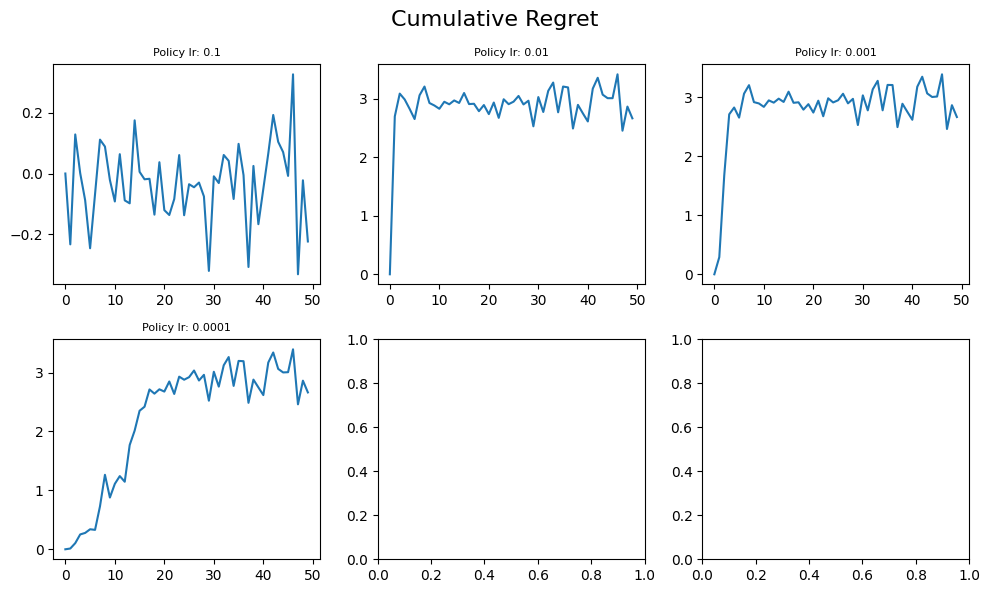

-0.03337387
2.865678
2.7841275
2.2323492


In [ ]:
plot_loss_dict(data_cumul_regrets, "Cumulative Regret")
for key, value in data_cumul_regrets.items():
    print(jnp.mean(jnp.array(value)))

# Solve Entire Problem

## Compute Exploitability

In [ ]:
def compute_exploitability(auction: BanditAuction,
                        mechanism_network,
                        mechanism_params,
                        policy_network,
                        num_epochs = 1000,
                        num_samples = 32,
                        learning_rate_exp = 1e-3,
                        print_iter = 50
                        ):
    cumul_regrets = []
    prng = hk.PRNGSequence(SEED)

    # Initialize mechanism and policy params
    mechanism = Mechanism(mechanism_network, mechanism_params)
    policy_params = policy_network.init(next(prng), auction.get_initial_belief_state(auction.get_initial_state(next(prng))), auction)

    # Create optimizer
    policy_optimizer = optax.adam(learning_rate_exp)
    policy_opt_state = policy_optimizer.init(policy_params)


    def temperature_schedule_exp(epoch, tau0=1.0, tau_min=0.1, decay_rate=0.005):
        return jnp.maximum(tau_min, tau0 * jnp.exp(-decay_rate * epoch))


    @jax.jit
    def cumulative_regret_loss(policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        policy = BoundedContPolicy(policy_network, policy_params)
        cumul_regret = AuctionSimulator.estimate_cumulative_regret(auction, mechanism, policy, num_samples, key)
        # cumul_regret = jnp.maximum(0.0, cumul_regret)
        return cumul_regret


    @jax.jit
    def get_grads(policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        cumul_regret, policy_network_grad = jax.value_and_grad(cumulative_regret_loss)(policy_params, key, temperature)
        return cumul_regret, policy_network_grad


    @jax.jit
    def update_params(policy_params, policy_opt_state, key: jax.random.PRNGKey, temperature: float):
        cumul_regret, policy_network_grad = get_grads(policy_params, key, temperature)
        # print(jax.make_jaxpr(get_grads)(policy_params, key))

        # Print norm of policy_network_grad to check if the update is correctly implememted
        # print(f"Policy network grad: {jax.tree_map(lambda g: jnp.linalg.norm(g), policy_network_grad)}")


        # Policy Network Update
        policy_network_grad = jax.tree_util.tree_map(lambda x: -x, policy_network_grad)
        policy_updates, policy_opt_state = policy_optimizer.update(policy_network_grad, policy_opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, policy_updates)

        return cumul_regret, policy_params, policy_opt_state


    for epoch in range(num_epochs):
        key = next(prng)
        temperature = temperature_schedule_exp(epoch)

        cumul_regret, policy_params, policy_opt_state = update_params(policy_params, policy_opt_state, key, temperature)

        if epoch % print_iter == 0:
          print(f"\t==================== Exp Epoch {epoch} ====================")
          print(f"\tExploitability: {cumul_regret}")
        cumul_regrets.append(cumul_regret)

    policy = BoundedContPolicy(policy_network, policy_params)

    return cumul_regrets, policy

## Method 1: GDA for Min-Max Method
Do binary search on target principal objective value $\tau$, and for each $\tau$, use Gradient Descent Ascent to solve
$$ \min_{\theta} \max_{\pi} |f(\theta)-\tau| + g(\theta, \pi)$$
where $f(\theta)$ is the cumulative profit of the mechanism assuming the buyers always truthfully report, and $g(\theta, \pi)$ is the cumulative regret of policy $\pi$ respect to the truthful reporting policy, under mechanism $\theta$.

In [ ]:
def GDA_obj(auction: BanditAuction,
                        mechanism_network,
                        policy_network,
                        profit_goal,
                        num_epochs = 1000,
                        num_iters_per_batch = 1,
                        num_samples = 32,
                        learning_rates = (1e-4, 5e-6),
                        print_iter = 50,
                        alpha = 1e5,
                        beta = 1e3,
                        compute_exploit = False,
                        num_epochs_exp = 1000,
                        learning_rate_exp = 1e-3,
                        print_iter_exp = 50
                        ):
    profit_losses = []
    cumul_regret_losses = []
    ir_losses = []
    total_losses = []
    exploitabilities = []
    good_mechs = []

    prng = hk.PRNGSequence(SEED)

    # Initialize mechanism and policy params
    mechanism_params = mechanism_network.init(next(prng), auction.get_initial_state(next(prng)), jnp.zeros((auction.num_buyers, auction.num_goods)), auction)
    policy_params = policy_network.init(next(prng), auction.get_initial_belief_state(auction.get_initial_state(next(prng))), auction)
    # policy_params = make_identity_policy_params(
    #                                     policy_params,
    #                                     buyer_layer_keys=buyer_layer_keys,
    #                                     buyer_hidden_keys=buyer_hidden_keys,
    #                                     marginal_proj_keys=marginal_proj_keys,
    #                                     num_types=auction.num_types,
    #                                 )
    # Create optimizers
    mechanism_optimizer = optax.adam(learning_rates[0])
    mechanism_opt_state = mechanism_optimizer.init(mechanism_params)
    policy_optimizer = optax.adam(learning_rates[1])
    policy_opt_state = policy_optimizer.init(policy_params)


    def temperature_schedule_exp(epoch, tau0=1.0, tau_min=0.1, decay_rate=0.005):
        return jnp.maximum(tau_min, tau0 * jnp.exp(-decay_rate * epoch))


    @jax.jit
    def cumulative_regret_loss_fn(mechanism_params: hk.Params, policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        policy = BoundedContPolicy(policy_network, policy_params)
        cumul_regret = AuctionSimulator.estimate_cumulative_regret(auction, mechanism, policy, num_samples, key)
        return cumul_regret

    @jax.jit
    def ir_loss_fn(mechanism_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        policy = BoundedContPolicy(policy_network, policy_params)
        expected_cumul_rewards = AuctionSimulator.estimate_cumulative_rewards(auction, mechanism, num_samples, key)
        return jnp.sum(jnp.abs(expected_cumul_rewards))

    @jax.jit
    def profit_loss_fn(mechanism_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        policy = BoundedContPolicy(policy_network, policy_params)
        cumulative_profit = AuctionSimulator.estimate_cumulative_profit(auction, mechanism, num_samples, key)
        return profit_goal - cumulative_profit
        # return jnp.abs(profit_goal - cumulative_profit)

    @jax.jit
    def total_loss_fn(mechanism_params: hk.Params, policy_params: hk.Params, key: jax.random.PRNGKey, temperature: float):
        cumul_regret_loss = cumulative_regret_loss_fn(mechanism_params, policy_params, key, temperature)
        profit_loss = profit_loss_fn(mechanism_params, key, temperature)
        ir_loss = ir_loss_fn(mechanism_params, key, temperature)
        return alpha * cumul_regret_loss +  jnp.abs(profit_loss) + beta * ir_loss


    @jax.jit
    def get_grads(mechanism_params:  hk.Params, policy_params:  hk.Params, key: jax.random.PRNGKey, temperature: float):
        total_loss, (mechanism_network_grad, policy_network_grad) = jax.value_and_grad(total_loss_fn, argnums=[0, 1])(mechanism_params, policy_params, key, temperature)
        return total_loss, mechanism_network_grad, policy_network_grad


    @jax.jit
    def update_params(mechanism_params, policy_params, mechanism_opt_state, policy_opt_state, key: jax.random.PRNGKey, temperature: float):
        total_loss, mechanism_network_grad, policy_network_grad = get_grads(mechanism_params, policy_params, key, temperature)
        # mechanism Network Update
        mechanism_updates, mechanism_opt_state = mechanism_optimizer.update(mechanism_network_grad, mechanism_opt_state, mechanism_params)
        mechanism_params = optax.apply_updates(mechanism_params, mechanism_updates)

        # policy Network Update
        policy_network_grad = jax.tree_util.tree_map(lambda x: -x, policy_network_grad)
        policy_updates, policy_opt_state = policy_optimizer.update(policy_network_grad, policy_opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, policy_updates)

        return total_loss, (mechanism_params, policy_params), (mechanism_opt_state, policy_opt_state)


    for epoch in range(num_epochs):
        key = next(prng)
        temperature = temperature_schedule_exp(epoch)

        for _ in range(num_iters_per_batch):
            total_loss, (mechanism_params, policy_params), (mechanism_opt_state, policy_opt_state) = update_params(mechanism_params, policy_params, mechanism_opt_state, policy_opt_state, next(prng), temperature)

        if epoch % print_iter == 0:
          print(f"==================== Epoch {epoch} ====================")
          cumul_regret_loss = cumulative_regret_loss_fn(mechanism_params, policy_params, next(prng), temperature)
          profit_loss = profit_loss_fn(mechanism_params, next(prng), temperature)
          ir_loss = ir_loss_fn(mechanism_params, next(prng), temperature)
          print(f"Cumulative Regret Loss: {cumul_regret_loss}")
          print(f"Profit Loss: {profit_loss}")
          print(f"IR Loss: {ir_loss}")
          cumul_regret_losses.append(cumul_regret_loss)
          profit_losses.append(profit_loss)
          ir_losses.append(ir_loss)
          # total_losses.append(total_loss)

          if compute_exploit:
            exploits, _ = compute_exploitability(auction, mechanism_network, mechanism_params, policy_network, num_epochs_exp, num_samples, learning_rate_exp, print_iter_exp)
            avg_exploit = jnp.mean(jnp.array(exploits[-50:]))
            print(f"Exploitability: {avg_exploit}")
            exploitabilities.append(avg_exploit)

            if profit_loss <= 0.1 and ir_loss <= 0.1 and avg_exploit <= 0.1:
              good_mech_tuple = (mechanism_params, profit_loss, ir_loss, avg_exploit)
              good_mechs.append(good_mech_tuple)
              break

    mechanism = Mechanism(mechanism_network, mechanism_params)
    policy = BoundedContPolicy(policy_network, policy_params)
    return cumul_regret_losses, profit_losses, ir_losses, exploitabilities, good_mechs, mechanism, policy

In [ ]:
mech_lr_sweep = [1e-4]
policy_lr_sweep = [1e-4]
alpha_sweep = [0.1] # cumul_regret weight
beta_sweep = [1] # ir loss weight
# 17.5 is done
# 17.75 failed
profit_goal_sweep = [17.65]





num_samples = 32
num_epochs = 10000
num_iters_per_batch = 2
print_iter = 50

compute_exploit = True
num_epochs_exp = 1000
learning_rate_exp = 1e-3
print_iter_exp = 500


# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
# policy_network = hk.without_apply_rng(hk.transform(_policy_network))
policy_network = build_bounded_policy_net(auction.d_priv, auction.d_pub, auction.num_goods, hidden=128, residual_init_std=1.0, cproj_init_std=0.0)


# data_cumul_regret_loss_gda = {f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}": [] for mech_lr, policy_lr, alpha in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep)}
data_profit_loss_gda = {f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}": [] for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep)}
data_ir_loss_gda = {f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}": [] for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep)}
data_exploitability_gda = {f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}": [] for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep)}
data_mechanism_gda = {f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}": [] for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep)}
for mech_lr, policy_lr, alpha, beta, profit_goal  in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep):
    print(f"==================== mech. lr: {mech_lr}, policy lr: {policy_lr}, alpha: {alpha}, beta: {beta}, profit goal: {profit_goal} ====================")
    cumul_regret_losses, profit_losses, ir_losses, exploitabilities, good_mechs, _, _= GDA_obj(auction, mechanism_network, policy_network, profit_goal, num_epochs,
                                                                     num_iters_per_batch, num_samples, (mech_lr, policy_lr), print_iter, alpha, beta,
                                                                     compute_exploit, num_epochs_exp, learning_rate_exp, print_iter_exp)
    # data_cumul_regret_loss_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}"] = cumul_regret_losses
    data_profit_loss_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"] = profit_losses
    data_ir_loss_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"] = ir_losses
    data_exploitability_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"] = exploitabilities
    data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"] = good_mechs

==================== mech. lr: 0.0001, policy lr: 0.0001, alpha: 0.1, beta: 1, profit goal: 17.65 ====================
==================== Epoch 0 ====================
Cumulative Regret Loss: -0.5021162629127502
Profit Loss: 17.792495727539062
IR Loss: 8.263193130493164
	==================== Exp Epoch 0 ====================
	Exploitability: -1.093075156211853
	==================== Exp Epoch 500 ====================
	Exploitability: 2.228738784790039
Exploitability: 2.3080339431762695
==================== Epoch 50 ====================
Cumulative Regret Loss: 3.219454050064087
Profit Loss: 0.9660873413085938
IR Loss: 0.6975034475326538
	==================== Exp Epoch 0 ====================
	Exploitability: -3.964881420135498
	==================== Exp Epoch 500 ====================
	Exploitability: 4.02235746383667
Exploitability: 4.896800518035889
==================== Epoch 100 ====================
Cumulative Regret Loss: -3.284975051879883
Profit Loss: 1.686753273010254
IR Loss: 0.7495

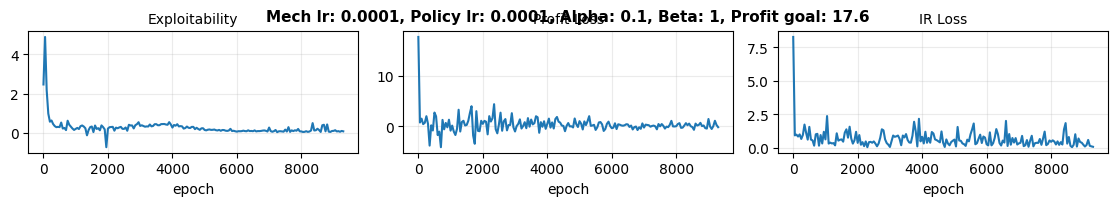

In [ ]:
plot_loss_dicts([data_exploitability_gda, data_profit_loss_gda, data_ir_loss_gda], print_iter, dict_names=['Exploitability', 'Profit Loss', 'IR Loss'])

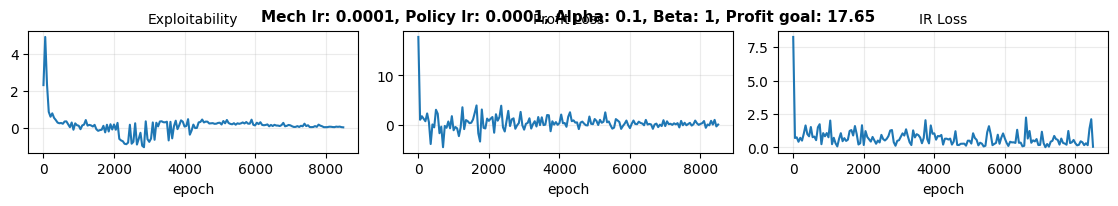

In [ ]:
plot_loss_dicts([data_exploitability_gda, data_profit_loss_gda, data_ir_loss_gda], dict_names=['Exploitability', 'Profit Loss', 'IR Loss'])

In [ ]:
for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep):
    if len(data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]) > 0:
        print(f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}", len(data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]))
    for good_mech_tuple in data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]:
        mechanism_params, profit_loss, ir_loss, exploitability = good_mech_tuple
        print(f"profit_loss: {profit_loss}, ir_loss: {ir_loss}, exploitability: {exploitability}, profit_goal: {profit_goal}")

Mech lr: 0.0001, Policy lr: 0.0001, Alpha: 0.1, Beta: 1, Profit goal: 17.65 1
profit_loss: -0.0025081634521484375, ir_loss: 0.04247262328863144, exploitability: 0.04034224897623062, profit_goal: 17.65


In [ ]:
# Create the directory if it doesn't exist
save_dir = "data"
os.makedirs(save_dir, exist_ok=True)

# Define the filename
filename = os.path.join(save_dir, "cont_data_mechanism_gda_17_65.pkl")

# Save the dictionary using pickle
with open(filename, 'wb') as f:
    pickle.dump(data_mechanism_gda, f)

print(f"Data saved to {filename}")


Data saved to data/cont_data_mechanism_gda_17_65.pkl


### Test the output mechanism

In [ ]:
# Define the filename
save_dir = "data"
good_params_filename = os.path.join(save_dir, "cont_data_mechanism_gda_17_65.pkl")

# Load the dictionary using pickle
try:
    with open(good_params_filename, 'rb') as f:
        data_mechanism_gda = pickle.load(f)
    print(f"Data loaded successfully from {good_params_filename}")
except FileNotFoundError:
    print(f"File not found: {good_params_filename}. Please ensure the file exists in the '{save_dir}' directory.")
except Exception as e:
    print(f"An error occurred while loading the file: {e}")

Data loaded successfully from data/cont_data_mechanism_gda_17_65.pkl


In [ ]:
mech_lr_sweep = [1e-4]
policy_lr_sweep = [1e-4]
alpha_sweep = [0.1] # cumul_regret weight
beta_sweep = [1] # ir loss weight
# 13.75 is done
profit_goal_sweep = [17.65]

for mech_lr, policy_lr, alpha, beta, profit_goal in product(mech_lr_sweep, policy_lr_sweep, alpha_sweep, beta_sweep, profit_goal_sweep):
    if len(data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]) > 0:
        print(f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}:", len(data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]))
    for good_mech_tuple in data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]:
        mechanism_params, profit_loss, ir_loss, exploitability = good_mech_tuple
        print(f"profit_loss: {profit_loss}, ir_loss: {ir_loss}, exploitability: {exploitability}, profit_goal: {profit_goal}")


Mech lr: 0.0001, Policy lr: 0.0001, Alpha: 0.1, Beta: 1, Profit goal: 17.65: 1
profit_loss: -0.0025081634521484375, ir_loss: 0.04247262328863144, exploitability: 0.04034224897623062, profit_goal: 17.65


In [ ]:
import random

mech_lr = 1e-4
policy_lr = 1e-4
alpha = 0.1
beta = 1
profit_goal = 17.65
good_mech_tuples = data_mechanism_gda[f"Mech lr: {mech_lr}, Policy lr: {policy_lr}, Alpha: {alpha}, Beta: {beta}, Profit goal: {profit_goal}"]
mechanism_params, profit_loss, ir_loss, exploitability = good_mech_tuples[0]
print(f"profit_loss: {profit_loss}, ir_loss: {ir_loss}, exploitability: {exploitability}")

policy_lr_sweep = [1e-2, 1e-3, 1e-4]
num_samples = 32
num_epochs = 1000
num_iters_per_batch = 1
print_iter = 20

# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
policy_network = build_bounded_policy_net(auction.d_priv, auction.d_pub, auction.num_goods, hidden=128, residual_init_std=1.0, cproj_init_std=0.0)
# Initialize network parameters
seed = 42

# policy_params = policy_network.init(key, auction.get_initial_belief_state(), auction)

# Generate 30 random seeds
random_seeds = [random.getrandbits(32) for _ in range(30)]
exploitabilities = []
for random_seed in random_seeds:
  # data_cumul_regrets = {f"Policy lr: {policy_lr}": [] for policy_lr in policy_lr_sweep}
  highest_exploitability = -1e5
  for policy_lr in policy_lr_sweep:
      print(f"==================== Policy lr: {policy_lr} ====================")
      cumul_regrets, policy = maximize_cumul_regret(auction,
                          mechanism_network,
                          mechanism_params,
                          policy_network,
                          num_epochs,
                          num_iters_per_batch,
                          num_samples,
                          policy_lr,
                          print_iter,
                          initial_truthful=False,
                          seed = random_seed
                          )
      avg_exploit = jnp.mean(jnp.array(cumul_regrets[-5:]))
      print(f"avg_exploit: {avg_exploit}")
      if avg_exploit > highest_exploitability:
          highest_exploitability = avg_exploit
  # print(f"Exploitability: {highest_exploitability}")
  # if highest_exploitability > -0.5:
  exploitabilities.append(highest_exploitability)

Streaming output truncated to the last 5000 lines.
Cumulative Regret: 0.027593206614255905
avg_exploit: 0.021043434739112854
==================== Policy lr: 0.0001 ====================
==================== Epoch 0 ====================
Cumulative Regret: -0.28810060024261475
==================== Epoch 20 ====================
Cumulative Regret: -0.09820270538330078
==================== Epoch 40 ====================
Cumulative Regret: -0.046532031148672104
==================== Epoch 60 ====================
Cumulative Regret: -0.0632859319448471
==================== Epoch 80 ====================
Cumulative Regret: -0.03390264883637428
==================== Epoch 100 ====================
Cumulative Regret: 0.0582638680934906
==================== Epoch 120 ====================
Cumulative Regret: 9.783406858332455e-05
==================== Epoch 140 ====================
Cumulative Regret: -0.009479770436882973
==================== Epoch 160 ====================
Cumulative Regret: 0.057171691209

In [ ]:
print(jnp.mean(jnp.array(exploitabilities)))

0.049030904


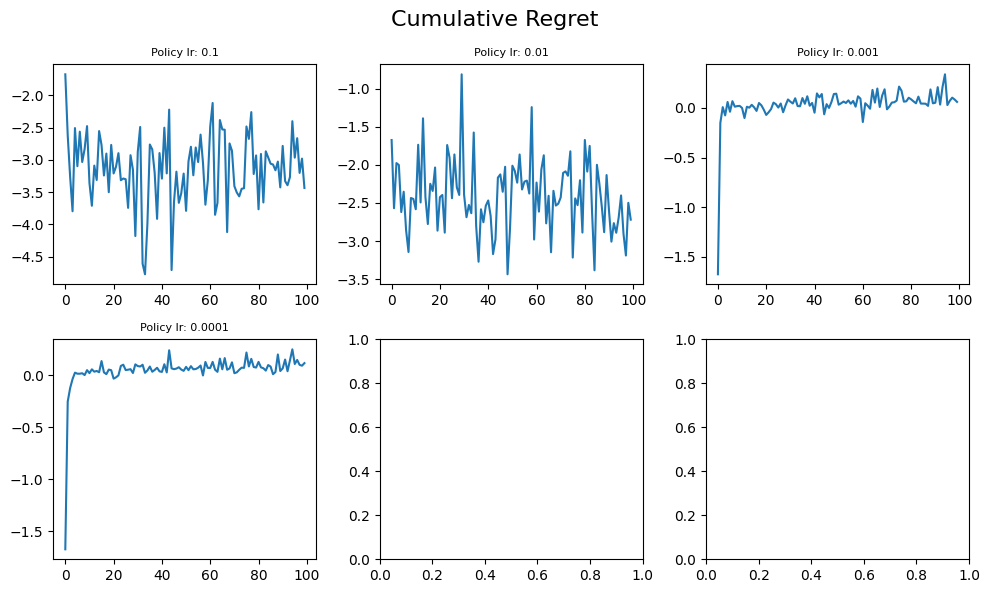

-3.0787218
-2.4175482
0.078258894
0.09023038


In [ ]:
plot_loss_dict(data_cumul_regrets, "Cumulative Regret")
for key, value in data_cumul_regrets.items():
    print(jnp.mean(jnp.array(value[-50:])))

In [ ]:
plot_loss_dict(data_cumul_regrets, "Cumulative Regret")
for key, value in data_cumul_regrets.items():
    print(jnp.mean(jnp.array(value[-50:])))

## Method 2: Nested GDA for Min-Max Method

In [ ]:
# ============================================================
# NESTED GD for CONTINUOUS type, SINGLE item
# Deviation policy class: BoundedContPolicy (deterministic)
#
# Goal (feasibility-style, same as your Method 1 objective):
#   For each mechanism theta:
#     (inner)    approximately maximize cumulative regret over policy params w
#     (outer)    update theta to reduce feasibility objective using w*(theta)
#
# This code is intentionally VERY close to the discrete nested_GD version you used,
# but adapted to the continuous notebook:
#   - use BoundedContPolicy instead of DiffPolicy
#   - keep your AuctionSimulator.estimate_cumulative_* APIs
#   - same key-splitting / +part penalties / early stop structure
#
# Assumes your notebook already defines:
#   BanditAuction, State, BeliefState, Mechanism, BoundedContPolicy, AuctionSimulator
#   mechanism_network, policy_network (hk.transform or hk.without_apply_rng)
#   SEED (int), and `auction` instance is created.
# ============================================================

import jax
import jax.numpy as jnp
import haiku as hk
import optax


def nested_GD_obj_cont_bounded(
    auction: BanditAuction,
    mechanism_network,
    policy_network,
    profit_goal: float,

    # Outer loop (mechanism)
    num_outer_epochs: int = 2000,
    outer_steps_per_epoch: int = 1,
    lr_theta: float = 1e-4,

    # Inner loop (policy oracle)
    num_inner_steps: int = 300,
    lr_w: float = 3e-4,
    inner_opt_reset_each_outer: bool = False,

    # Monte Carlo samples (train)
    num_samples_train: int = 64,

    # Loss weights
    alpha: float = 1e5,
    beta: float = 1e3,

    # Diagnostics
    print_iter: int = 50,

    # Early stopping on plus-parts (recommended for feasibility)
    early_stop: bool = False,
    tol: float = 0.1,
    patience: int = 10,
):
    prng = hk.PRNGSequence(SEED)

    # -------------------------
    # Init mechanism params θ
    # -------------------------
    key_init = next(prng)
    init_state = auction.get_initial_state(next(prng))
    mechanism_params = mechanism_network.init(
        key_init,
        init_state,
        jnp.zeros((auction.num_buyers, auction.num_goods)),  # report placeholder
        auction,
    )

    # -------------------------
    # Init policy params w (belief state input)
    # -------------------------
    init_belief = auction.get_initial_belief_state(init_state)
    policy_params = policy_network.init(
        next(prng),
        init_belief,
        auction,
    )

    # -------------------------
    # Optimizers
    # -------------------------
    theta_opt = optax.adam(lr_theta)
    theta_opt_state = theta_opt.init(mechanism_params)

    w_opt = optax.adam(lr_w)
    w_opt_state = w_opt.init(policy_params)

    # -------------------------
    # Core estimators (TRAIN)
    #   IMPORTANT: capture networks via closure; do not pass them into jit args.
    #   Split keys so reg/profit/ir use independent randomness.
    # -------------------------
    @jax.jit
    def cumulative_regret(mechanism_params, policy_params, key):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        policy = BoundedContPolicy(policy_network, policy_params)
        return AuctionSimulator.estimate_cumulative_regret(
            auction, mechanism, policy, num_samples_train, key
        )

    @jax.jit
    def profit_gap(mechanism_params, key):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        prof = AuctionSimulator.estimate_cumulative_profit(
            auction, mechanism, num_samples_train, key
        )
        return profit_goal - prof

    @jax.jit
    def ir_loss(mechanism_params, key):
        mechanism = Mechanism(mechanism_network, mechanism_params)
        rewards = AuctionSimulator.estimate_relu_cumulative_rewards(
            auction, mechanism, num_samples_train*5, key
        )
        return jnp.sum(rewards)

    # -------------------------
    # Inner: gradient ASCENT on w to maximize regret
    # -------------------------
    @jax.jit
    def inner_step(mechanism_params, policy_params, w_opt_state, key):
        reg, grad_w = jax.value_and_grad(cumulative_regret, argnums=1)(
            mechanism_params, policy_params, key
        )
        # ascent: optax does descent, so negate gradient
        grad_w_ascent = jax.tree_util.tree_map(lambda g: -g, grad_w)
        updates, w_opt_state = w_opt.update(grad_w_ascent, w_opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, updates)
        return reg, policy_params, w_opt_state

    def maximize_regret_oracle(mechanism_params, policy_params, w_opt_state, steps: int):
        reg_last = 0.0
        for _ in range(steps):
            key = next(prng)
            reg_last, policy_params, w_opt_state = inner_step(
                mechanism_params, policy_params, w_opt_state, key
            )
        return reg_last, policy_params, w_opt_state

    # -------------------------
    # Outer: update θ using w*(θ)
    #   feasibility-style objective (very close to your discrete nested version):
    #     L(θ) = α * (Regret(θ, w*))_+ + (profit_goal - Profit(θ))_+ + β * IR(θ)
    # -------------------------
    @jax.jit
    def total_loss_with_oracle(mechanism_params, policy_params_star, key):
        k1, k2, k3 = jax.random.split(key, 3)
        reg = cumulative_regret(mechanism_params, policy_params_star, k1)
        gap = profit_gap(mechanism_params, k2)
        ir  = ir_loss(mechanism_params, k3)

        reg_plus = jnp.maximum(0.0, reg)
        gap_plus = jnp.maximum(0.0, gap)

        loss = alpha * reg_plus + gap_plus + beta * ir
        return loss, (reg, gap, ir, reg_plus, gap_plus)

    @jax.jit
    def outer_step(mechanism_params, theta_opt_state, policy_params_star, key):
        (loss, aux), grad_theta = jax.value_and_grad(
            total_loss_with_oracle, argnums=0, has_aux=True
        )(mechanism_params, policy_params_star, key)
        updates, theta_opt_state = theta_opt.update(grad_theta, theta_opt_state, mechanism_params)
        mechanism_params = optax.apply_updates(mechanism_params, updates)
        return loss, aux, mechanism_params, theta_opt_state

    # -------------------------
    # Logs
    # -------------------------
    logs = {
        "loss": [], "reg": [], "gap": [], "ir": [],
        "reg_plus": [], "gap_plus": [],
        "oracle_reg_last": [],
        "good_mech":[],
    }

    sat_count = 0

    # -------------------------
    # Training loop
    # -------------------------
    for outer_epoch in range(num_outer_epochs):

        # Optional: reset oracle each outer epoch (helps avoid path dependence)
        if inner_opt_reset_each_outer and outer_epoch > 0:
            init_state = auction.get_initial_state(next(prng))
            init_belief = auction.get_initial_belief_state(init_state)
            policy_params = policy_network.init(next(prng), init_belief, auction)
            w_opt_state = w_opt.init(policy_params)

        # --- Inner oracle: approximate argmax_w Regret(θ,w)
        reg_star, policy_params, w_opt_state = maximize_regret_oracle(
            mechanism_params, policy_params, w_opt_state, num_inner_steps
        )
        policy_params_star = policy_params

        # --- Outer update(s)
        for _ in range(outer_steps_per_epoch):
            key_outer = next(prng)
            loss, (reg, gap, ir, reg_plus, gap_plus), mechanism_params, theta_opt_state = outer_step(
                mechanism_params, theta_opt_state, policy_params_star, key_outer
            )

        # logging (python floats)
        loss_val = float(loss)
        reg_val = float(reg)
        gap_val = float(gap)
        ir_val  = float(ir)
        regp_val = float(reg_plus)
        gapp_val = float(gap_plus)
        reg_star_val = float(reg_star)

        logs["loss"].append(loss_val)
        logs["reg"].append(reg_val)
        logs["gap"].append(gap_val)
        logs["ir"].append(ir_val)
        logs["reg_plus"].append(regp_val)
        logs["gap_plus"].append(gapp_val)
        logs["oracle_reg_last"].append(reg_star_val)

        if outer_epoch % print_iter == 0:
            print(f"==================== Outer Epoch {outer_epoch} ====================")
            print(f"oracle regret last (train): {reg_star_val:.6f}")
            print(f"reg (eval in loss):         {reg_val:.6f}   reg_+={regp_val:.6f}")
            print(f"gap (profit_goal-profit):   {gap_val:.6f}   gap_+={gapp_val:.6f}")
            print(f"ir_loss:                    {ir_val:.6f}")
            print(f"total loss:                 {loss_val:.6f}")

        # Early stopping uses +parts (consistent with feasibility)
        if early_stop:
            ok = (reg_val <= tol) and (ir_val <= tol*10) and (gap_val <= tol)
            if ok:
                logs["good_mech"].append((mechanism_params, policy_params_star, reg_val, ir_val, gap_val))
            sat_count = sat_count + 1 if ok else 0
            if sat_count >= patience:
                print(
                    f"[EARLY STOP] met for {patience} consecutive epochs at epoch={outer_epoch}\n"
                    f"  reg_+={regp_val:.6f}, ir={ir_val:.6f}, gap_+={gapp_val:.6f} (tol={tol})"
                )
                break

    trained_mechanism = Mechanism(mechanism_network, mechanism_params)
    trained_oracle_policy = BoundedContPolicy(policy_network, policy_params)  # last oracle params
    return logs, trained_mechanism, trained_oracle_policy, mechanism_params, policy_params


### Train

In [ ]:
profit_goal = 18.5  # your target δ

# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
# policy_network = hk.without_apply_rng(hk.transform(_policy_network))
policy_network = build_bounded_policy_net(auction.d_priv, auction.d_pub, auction.num_goods, hidden=128, residual_init_std=1.0, cproj_init_std=0.0)

logs, trained_mechanism, trained_oracle_policy, theta_final, w_final = nested_GD_obj_cont_bounded(
    auction=auction,
    mechanism_network=mechanism_network,
    policy_network=policy_network,
    profit_goal=profit_goal,

    # Outer
    num_outer_epochs=2000,
    outer_steps_per_epoch=1,
    lr_theta=1e-4,

    # Inner oracle
    num_inner_steps=400,
    lr_w=5e-4,
    inner_opt_reset_each_outer=False,

    # MC
    num_samples_train=64,

    # weights
    alpha=1,
    beta=20,

    print_iter=50,
    early_stop=True,
    tol=0.01
)


==================== Outer Epoch 0 ====================
oracle regret last (train): 1.714246
reg (eval in loss):         1.681402   reg_+=1.681402
gap (profit_goal-profit):   19.272665   gap_+=19.272665
ir_loss:                    0.000000
total loss:                 20.954067
==================== Outer Epoch 50 ====================
oracle regret last (train): 1.307976
reg (eval in loss):         1.271747   reg_+=1.271747
gap (profit_goal-profit):   3.641432   gap_+=3.641432
ir_loss:                    0.008069
total loss:                 5.074560
==================== Outer Epoch 100 ====================
oracle regret last (train): 0.409069
reg (eval in loss):         0.383709   reg_+=0.383709
gap (profit_goal-profit):   1.294558   gap_+=1.294558
ir_loss:                    0.011672
total loss:                 1.911702
==================== Outer Epoch 150 ====================
oracle regret last (train): 0.087568
reg (eval in loss):         0.086542   reg_+=0.086542
gap (profit_goal-pro

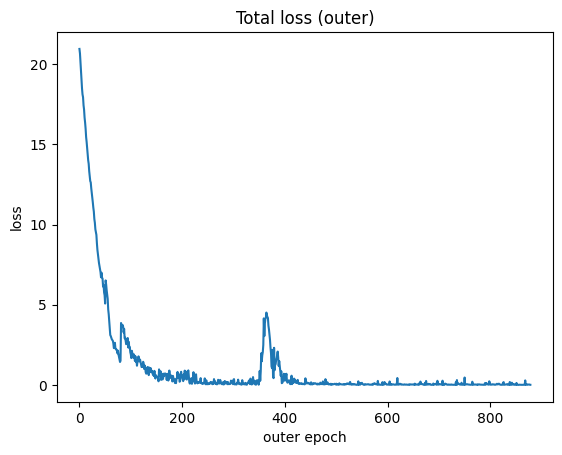

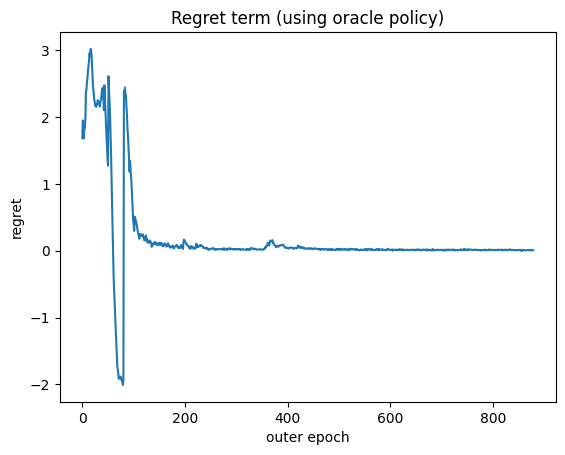

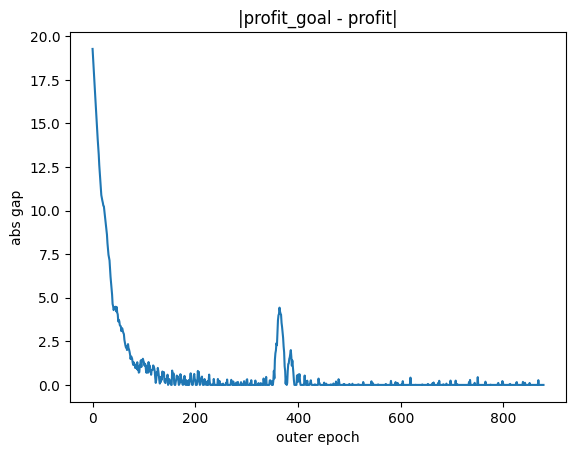

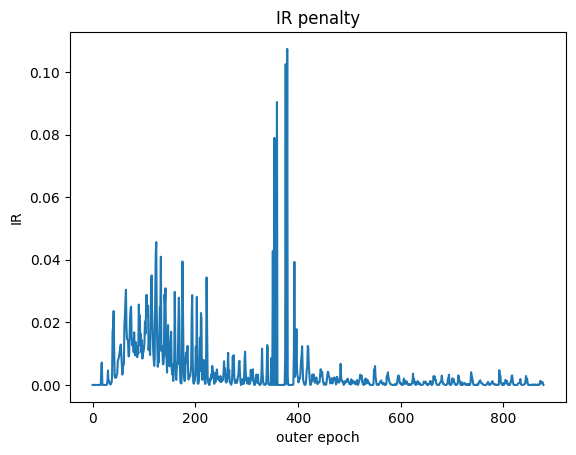

In [ ]:
# 4) Quick diagnostics after training
# -------------------------
import matplotlib.pyplot as plt

plt.figure()
plt.plot(logs["loss"])
plt.title("Total loss (outer)")
plt.xlabel("outer epoch")
plt.ylabel("loss")
plt.show()

plt.figure()
plt.plot(logs["reg"])
plt.title("Regret term (using oracle policy)")
plt.xlabel("outer epoch")
plt.ylabel("regret")
plt.show()

plt.figure()
plt.plot([jnp.maximum(0.0, x) for x in logs["gap"]])
plt.title("|profit_goal - profit|")
plt.xlabel("outer epoch")
plt.ylabel("abs gap")
plt.show()

plt.figure()
plt.plot(logs["ir"])
plt.title("IR penalty")
plt.xlabel("outer epoch")
plt.ylabel("IR")
plt.show()

In [ ]:
print(len(logs["good_mech"]))

118


In [ ]:
15.5 ok
15.75 ok

In [ ]:
import os, pickle

save_dir = "./_runs/nested/cont_multi_18_5"
os.makedirs(save_dir, exist_ok=True)

logs_path = os.path.join(save_dir, "cont_multi_logs.pkl")
mech_params_path = os.path.join(save_dir, "cont_multi_mech_params.pkl")
policy_params_path = os.path.join(save_dir, "cont_multi_policy_params.pkl")

with open(logs_path, "wb") as f:
    pickle.dump(logs, f)

with open(mech_params_path, "wb") as f:
    pickle.dump(theta_final, f)

with open(policy_params_path, "wb") as f:
    pickle.dump(w_final, f)

print("Saved:")
print(" ", logs_path)
print(" ", mech_params_path)
print(" ", policy_params_path)

Saved:
  ./_runs/nested/cont_multi_18_5/cont_multi_logs.pkl
  ./_runs/nested/cont_multi_18_5/cont_multi_mech_params.pkl
  ./_runs/nested/cont_multi_18_5/cont_multi_policy_params.pkl


currently 18 is the best

### Test the output mechanism

In [ ]:
trained_mechanism_params, trained_oracle_policy_params = theta_final, w_final

#### IR: 3.262756945332512e-05

In [ ]:
all_saved_mech_params = [mech_params for (mech_params, policy_params, _, _, _) in logs["good_mech"]]

In [ ]:
def select_lowest_mean_ir(
    auction,
    mechanism_network,
    mech_params_list,
    num_samples: int = 256,
    num_keys: int = 32,
    seed: int = 0,
):
    keys = jax.random.split(jax.random.PRNGKey(seed), num_keys)

    best_idx = None
    best_ir_mean = float("inf")
    all_stats = []

    for i, params in enumerate(mech_params_list):
        mechanism = Mechanism(mechanism_network, params)

        ir_vals = []
        for k in keys:
            rewards = AuctionSimulator.estimate_relu_cumulative_rewards(
                auction=auction,
                mechanism=mechanism,
                num_samples=num_samples,
                key=k,
            )
            ir_vals.append(jnp.sum(rewards))

        ir_vals = jnp.stack(ir_vals)
        ir_mean = float(ir_vals.mean())

        stats = {
            "idx": i,
            "ir_mean": ir_mean,
            "ir_std": float(ir_vals.std()),
            "ir_max": float(ir_vals.max()),
            "ir_p95": float(jnp.quantile(ir_vals, 0.95)),
        }
        all_stats.append(stats)

        if ir_mean < best_ir_mean:
            best_ir_mean = ir_mean
            best_idx = i

    return best_idx, mech_params_list[best_idx], all_stats

best_idx, best_params, ir_stats = select_lowest_mean_ir(
    auction=auction,
    mechanism_network=mechanism_network,
    mech_params_list=all_saved_mech_params,
    num_samples=256,
    num_keys=32,
    seed=123,
)

In [ ]:
print(f"Best mechanism index: {best_idx}")
# print("IR stats for all candidates:")
# for s in ir_stats:
#     print(s)
print(ir_stats[best_idx])
print(logs["good_mech"][0][2:])
good_mech_params, good_policy_params, _, _, _ = logs["good_mech"][best_idx]

Best mechanism index: 94
{'idx': 94, 'ir_mean': 3.776585799641907e-08, 'ir_std': 2.1027139496254676e-07, 'ir_max': 1.2085074558854103e-06, 'ir_p95': 0.0}
(0.009198920801281929, 0.0002631766546983272, -0.2444000244140625)


In [ ]:
low_ir_indices = []
for idx in range(len(all_saved_mech_params)):
    if ir_stats[idx]["ir_mean"] < 0.05:
        low_ir_indices.append(idx)

#### Profit: 18.151947021484375

In [ ]:
import jax
import jax.numpy as jnp
import optax
import haiku as hk

# -----------------------------
# Utilities
# -----------------------------
def _tree_l2_norm(pytree):
    leaves = jax.tree_util.tree_leaves(pytree)
    return float(jnp.sqrt(sum([jnp.sum(x * x) for x in leaves])))

def _stack(xs):
    return jnp.stack([jnp.asarray(x) for x in xs])

def _summary_stats(x: jnp.ndarray):
    return {
        "mean": float(jnp.mean(x)),
        "std": float(jnp.std(x)),
        "min": float(jnp.min(x)),
        "max": float(jnp.max(x)),
        "median": float(jnp.median(x)),
    }

def make_keys(base_seed: int, K: int):
    return jax.random.split(jax.random.PRNGKey(base_seed), K)


# ============================================================
# 1) Unbiased multi-key evaluation for fixed mechanism + (optional) fixed oracle policy
# ============================================================

def eval_mechanism_multikey(
    auction,
    mechanism_network,
    mechanism_params,
    profit_goal: float,
    num_samples: int = 256,
    keys=None,            # list/array of PRNGKeys, shape (K,2)
    base_seed: int = 0,
    K: int = 32,
    # IC evaluation:
    policy_network=None,
    policy_params=None,
    temperature: float = 0.2,
):
    """
    Evaluates:
      - profit (and profit_gap = profit_goal - profit)
      - IR loss = sum_i |U_i|
      - IC loss proxy = regret (and reg_+)

    If policy_network/policy_params are provided, IC regret is computed using that policy.
    Otherwise returns IC fields as None.

    Returns a dict with per-key arrays and summary stats.
    """
    if keys is None:
        keys = make_keys(base_seed, K)

    mechanism = Mechanism(mechanism_network, mechanism_params)
    policy = None
    if (policy_network is not None) and (policy_params is not None):
        policy = BoundedContPolicy(policy_network, policy_params)

    profits = []
    gaps = []
    ir_losses = []
    regrets = []

    for k in keys:
        prof = AuctionSimulator.estimate_cumulative_profit(
            auction, mechanism, num_samples=num_samples, key=k
        )
        gap = profit_goal - prof

        rewards = AuctionSimulator.estimate_cumulative_rewards(
            auction, mechanism, num_samples=num_samples, key=k
        )
        ir = jnp.sum(jnp.abs(rewards))

        profits.append(prof)
        gaps.append(gap)
        ir_losses.append(ir)

        if policy is not None:
            reg = AuctionSimulator.estimate_cumulative_regret(
                auction, mechanism, policy, num_samples=num_samples, key=k
            )
            regrets.append(reg)

    profits = _stack(profits)
    gaps = _stack(gaps)
    ir_losses = _stack(ir_losses)

    out = {
        "profit": profits,
        "profit_stats": _summary_stats(profits),
        "gap": gaps,
        "gap_stats": _summary_stats(gaps),
        "gap_plus": jnp.maximum(0.0, gaps),
        "gap_plus_stats": _summary_stats(jnp.maximum(0.0, gaps)),
        "abs_gap": jnp.abs(gaps),
        "abs_gap_stats": _summary_stats(jnp.abs(gaps)),
        "ir_loss": ir_losses,
        "ir_loss_stats": _summary_stats(ir_losses),
        "theta_norm": _tree_l2_norm(mechanism_params),
        "K": int(len(keys)),
        "num_samples": int(num_samples),
    }

    if policy is not None:
        regrets = _stack(regrets)
        out.update({
            "regret": regrets,
            "regret_stats": _summary_stats(regrets),
            "ic_loss": regrets,  # raw proxy (can be negative)
            "ic_plus": jnp.maximum(0.0, regrets),
            "ic_plus_stats": _summary_stats(jnp.maximum(0.0, regrets)),
            "abs_regret": jnp.abs(regrets),
            "abs_regret_stats": _summary_stats(jnp.abs(regrets)),
        })
    else:
        out.update({
            "regret": None,
            "regret_stats": None,
            "ic_plus": None,
            "ic_plus_stats": None,
        })

    return out


# ============================================================
# 2) Strong IC check: multi-restart oracle maximization over LR/steps/seeds,
#    then evaluate regret of the BEST oracle using multiple keys.
# ============================================================

def maximize_regret_oracle_once(
    auction,
    mechanism_network,
    mechanism_params,
    policy_network,
    init_policy_params,
    temperature: float,
    num_samples_inner: int,
    steps: int,
    lr: float,
    key_seed: int,
):
    """
    Runs gradient ASCENT on policy params to maximize cumulative regret for a fixed mechanism.
    Returns:
      - final_policy_params
      - final_regret_estimate (on last step key)
      - trajectory of regrets (python list of floats)
    """
    prng = hk.PRNGSequence(key_seed)
    mechanism = Mechanism(mechanism_network, mechanism_params)

    # optax does descent; we negate gradients for ascent
    opt = optax.adam(lr)
    opt_state = opt.init(init_policy_params)

    def regret_est(policy_params, key):
        policy = BoundedContPolicy(policy_network, policy_params)
        return AuctionSimulator.estimate_cumulative_regret(
            auction, mechanism, policy, num_samples=num_samples_inner, key=key
        )

    # jit only the grad step (no non-array args passed in; closure captures objects)
    @jax.jit
    def step_fn(policy_params, opt_state, key):
        reg, grad = jax.value_and_grad(regret_est)(policy_params, key)
        grad_ascent = jax.tree_util.tree_map(lambda g: -g, grad)
        updates, opt_state = opt.update(grad_ascent, opt_state, policy_params)
        policy_params = optax.apply_updates(policy_params, updates)
        return reg, policy_params, opt_state

    regs = []
    policy_params = init_policy_params
    reg_last = 0.0
    for _ in range(steps):
        key = next(prng)
        reg_last, policy_params, opt_state = step_fn(policy_params, opt_state, key)
        regs.append(float(reg_last))

    return policy_params, float(reg_last), regs


def strong_ic_evaluation(
    auction,
    mechanism_network,
    mechanism_params,
    policy_network,
    profit_goal: float,

    # Outer evaluation (unbiased multi-key)
    eval_num_samples: int = 256,
    eval_K: int = 32,
    eval_seed: int = 2026,

    # Oracle search grid
    temperature: float = 0.2,
    num_samples_inner: int = 64,
    steps_grid=(100, 200),
    lr_grid=(1e-4, 3e-4, 1e-3),
    num_restarts: int = 5,
    restart_seeds=(0, 1, 2, 3, 4),  # length >= num_restarts

    # Policy init
    policy_init_seed: int = 777,
):
    """
    1) Evaluates profit_gap and IR unbiasedly with multi-key.
    2) Searches for a high-regret oracle policy via multiple restarts and lr/steps grid.
    3) Evaluates IC regret of the best-found oracle unbiasedly with multi-key.
    """
    # fixed eval keys
    eval_keys = make_keys(eval_seed, eval_K)

    # Initialize a baseline policy params (same init each time unless you want randomness)
    prng_init = hk.PRNGSequence(policy_init_seed)
    init_state = auction.get_initial_state(next(prng_init))
    init_belief = auction.get_initial_belief_state(init_state)
    base_policy_params = policy_network.init(next(prng_init), init_belief, auction)

    # --- Oracle search ---
    best = {
        "policy_params": base_policy_params,
        "reg_last": -1e30,
        "lr": None,
        "steps": None,
        "seed": None,
        "reg_traj": None,
    }

    # choose seeds
    seeds = list(restart_seeds)[:num_restarts] if restart_seeds is not None else list(range(num_restarts))

    for s in seeds:
        # optionally re-init policy each restart with different seed
        prng_r = hk.PRNGSequence(policy_init_seed + 1000 + s)
        init_state_r = auction.get_initial_state(next(prng_r))
        init_belief_r = auction.get_initial_belief_state(init_state_r)
        init_params_r = policy_network.init(next(prng_r), init_belief_r, auction)

        for steps in steps_grid:
            for lr in lr_grid:
                pol, reg_last, reg_traj = maximize_regret_oracle_once(
                    auction=auction,
                    mechanism_network=mechanism_network,
                    mechanism_params=mechanism_params,
                    policy_network=policy_network,
                    init_policy_params=init_params_r,
                    temperature=temperature,
                    num_samples_inner=num_samples_inner,
                    steps=steps,
                    lr=lr,
                    key_seed=10_000 + s * 100 + int(steps) + int(lr * 1e6),
                )
                if reg_last > best["reg_last"]:
                    best.update({
                        "policy_params": pol,
                        "reg_last": reg_last,
                        "lr": lr,
                        "steps": steps,
                        "seed": s,
                        "reg_traj": reg_traj,
                    })

    # --- Unbiased evaluation with best oracle across many keys ---
    eval_out = eval_mechanism_multikey(
        auction=auction,
        mechanism_network=mechanism_network,
        mechanism_params=mechanism_params,
        profit_goal=profit_goal,
        num_samples=eval_num_samples,
        keys=eval_keys,
        policy_network=policy_network,
        policy_params=best["policy_params"],
        temperature=temperature,
    )

    # Attach oracle search info
    eval_out["oracle_search"] = {
        "best_reg_last_step_estimate": best["reg_last"],
        "best_lr": best["lr"],
        "best_steps": best["steps"],
        "best_restart_seed": best["seed"],
        "best_reg_traj_last10": best["reg_traj"][-10:] if best["reg_traj"] is not None else None,
        "inner_num_samples": num_samples_inner,
        "temperature": temperature,
    }

    return eval_out


# ============================================================
# 3) Pretty printer for results
# ============================================================

def print_eval_report(eval_out):
    ps = eval_out["profit_stats"]
    gs = eval_out["gap_stats"]
    gps = eval_out["gap_plus_stats"]
    irs = eval_out["ir_loss_stats"]

    print("===== Mechanism evaluation (multi-key) =====")
    print(f"K keys: {eval_out['K']}, num_samples per key: {eval_out['num_samples']}")
    print(f"theta ||.||_2: {eval_out['theta_norm']:.6f}")
    print("")
    print("[Profit]")
    print("  mean/std/min/max:", ps["mean"], ps["std"], ps["min"], ps["max"])
    print("[Gap = profit_goal - profit]")
    print("  mean/std/min/max:", gs["mean"], gs["std"], gs["min"], gs["max"])
    print("[Gap_+]")
    print("  mean/std/min/max:", gps["mean"], gps["std"], gps["min"], gps["max"])
    print("[IR loss = sum_i |U_i|]")
    print("  mean/std/min/max:", irs["mean"], irs["std"], irs["min"], irs["max"])

    if eval_out.get("regret") is not None:
        rs = eval_out["regret_stats"]
        rps = eval_out["ic_plus_stats"]
        print("")
        print("[IC proxy (regret)]")
        print("  mean/std/min/max:", rs["mean"], rs["std"], rs["min"], rs["max"])
        print("[IC loss = regret_+]")
        print("  mean/std/min/max:", rps["mean"], rps["std"], rps["min"], rps["max"])

    if "oracle_search" in eval_out:
        os = eval_out["oracle_search"]
        print("")
        print("===== Oracle robustness check =====")
        print("Best inner-run last-step regret estimate:", os["best_reg_last_step_estimate"])
        print("Best (lr, steps, restart_seed):", os["best_lr"], os["best_steps"], os["best_restart_seed"])
        print("Inner num_samples:", os["inner_num_samples"], "temperature:", os["temperature"])
        print("Last 10 regrets during best inner run:", os["best_reg_traj_last10"])

In [ ]:
keys = make_keys(2026, 32)
policy_network = build_bounded_policy_net(auction.d_priv, auction.d_pub, auction.num_goods, hidden=128, residual_init_std=1.0, cproj_init_std=0.0)
out = eval_mechanism_multikey(
    auction=auction,
    mechanism_network=mechanism_network,
    mechanism_params=good_mech_params,   # <-- your trained theta
    profit_goal=profit_goal,
    num_samples=256,
    keys=keys,
    policy_network=policy_network,
    policy_params=good_policy_params,
    temperature=0.2,
)

print_eval_report(out)

===== Mechanism evaluation (multi-key) =====
K keys: 32, num_samples per key: 256
theta ||.||_2: 26.207960

[Profit]
  mean/std/min/max: 15.821203231811523 0.06088212504982948 15.718360900878906 15.964692115783691
[Gap = profit_goal - profit]
  mean/std/min/max: -0.07120350003242493 0.06088212504982948 -0.2146921157836914 0.03163909912109375
[Gap_+]
  mean/std/min/max: 0.0024857819080352783 0.007828135043382645 0.0 0.03163909912109375
[IR loss = sum_i |U_i|]
  mean/std/min/max: 0.05293182283639908 0.026247486472129822 0.012905174866318703 0.11172398179769516

[IC proxy (regret)]
  mean/std/min/max: -0.01726618967950344 0.0013845140347257257 -0.020045552402734756 -0.014496601186692715
[IC loss = regret_+]
  mean/std/min/max: 0.0 0.0 0.0 0.0


In [ ]:
keys = make_keys(2026, 32)
profit_goal = 18
highest_profit = 0.0
highest_idx = -1
for i in range(len(low_ir_indices)):
    idx = low_ir_indices[i]
    print(f"{i}/{len(low_ir_indices)}......")
    out = eval_mechanism_multikey(
        auction=auction,
        mechanism_network=mechanism_network,
        mechanism_params=all_saved_mech_params[idx],
        profit_goal=profit_goal,
        num_samples=256,
        keys=keys,
        policy_network=policy_network,
        policy_params=good_policy_params,
        temperature=0.2,
    )
    if out["profit_stats"]["max"] > highest_profit:
        highest_profit = out["profit_stats"]["mean"] > highest_profit
        highest_profit = out["profit_stats"]["mean"]
        highest_idx = idx
print(highest_profit, out["profit_stats"]["std"])
print(ir_stats[highest_idx]["ir_mean"], ir_stats[highest_idx]["ir_std"])

0/118......
1/118......
2/118......
3/118......
4/118......
5/118......
6/118......
7/118......
8/118......
9/118......
10/118......
11/118......
12/118......
13/118......
14/118......
15/118......
16/118......
17/118......
18/118......
19/118......
20/118......
21/118......
22/118......
23/118......
24/118......
25/118......
26/118......
27/118......
28/118......
29/118......
30/118......
31/118......
32/118......
33/118......
34/118......
35/118......
36/118......
37/118......
38/118......
39/118......
40/118......
41/118......
42/118......
43/118......
44/118......
45/118......
46/118......
47/118......
48/118......
49/118......
50/118......
51/118......
52/118......
53/118......
54/118......
55/118......
56/118......
57/118......
58/118......
59/118......
60/118......
61/118......
62/118......
63/118......
64/118......
65/118......
66/118......
67/118......
68/118......
69/118......
70/118......
71/118......
72/118......
73/118......
74/118......
75/118......
76/118......
77/118...

#### IC: 0.004448449

In [ ]:
good_mech_params = all_saved_mech_params[highest_idx]

In [ ]:
import random

policy_lr_sweep = [1e-2, 1e-3, 1e-4]
num_samples = 64
num_epochs = 1000
num_iters_per_batch = 1
print_iter = 10

# Create Haiku networks
mechanism_network = hk.without_apply_rng(hk.transform(_mechanism_network))
policy_network = build_bounded_policy_net(auction.d_priv, auction.d_pub, auction.num_goods, hidden=128, residual_init_std=5.0, cproj_init_std=0.0)


# policy_params = policy_network.init(key, auction.get_initial_belief_state(), auction)
trained_mechanism_params = good_mech_params

random_seeds = [random.getrandbits(32) for _ in range(30)]
exploitabilities = []
for random_seed in random_seeds:
  # data_cumul_regrets = {f"Policy lr: {policy_lr}": [] for policy_lr in policy_lr_sweep}
  highest_exploitability = -1e5
  for policy_lr in policy_lr_sweep:
      print(f"==================== Policy lr: {policy_lr} ====================")
      cumul_regrets, policy = maximize_cumul_regret(auction,
                          mechanism_network,
                          good_mech_params,
                          policy_network,
                          num_epochs,
                          num_iters_per_batch,
                          num_samples,
                          policy_lr,
                          print_iter,
                          initial_truthful=False,
                          seed = random_seed
                          )
      avg_exploit = jnp.mean(jnp.array(cumul_regrets[-5:]))
      print(f"avg_exploit: {avg_exploit}")
      if avg_exploit > highest_exploitability:
          highest_exploitability = avg_exploit
  print(f"Exploitability: {highest_exploitability}")
  exploitabilities.append(highest_exploitability)

Streaming output truncated to the last 5000 lines.
==================== Epoch 290 ====================
Cumulative Regret: -0.01129814051091671
==================== Epoch 300 ====================
Cumulative Regret: -0.01618036814033985
==================== Epoch 310 ====================
Cumulative Regret: -0.016417324542999268
==================== Epoch 320 ====================
Cumulative Regret: -0.008979191072285175
==================== Epoch 330 ====================
Cumulative Regret: -0.008094778284430504
==================== Epoch 340 ====================
Cumulative Regret: -0.005045938305556774
==================== Epoch 350 ====================
Cumulative Regret: -0.00564942043274641
==================== Epoch 360 ====================
Cumulative Regret: -0.014146620407700539
==================== Epoch 370 ====================
Cumulative Regret: -0.007096525747328997
==================== Epoch 380 ====================
Cumulative Regret: -0.008763565681874752
==================== E

In [ ]:
print(jnp.mean(jnp.array(exploitabilities)))
print(jnp.std(jnp.array(exploitabilities)))

-0.054389276
0.19694431


## Method 3: Lagrangian Method